Phase 2 — GDELT Data Cleaning

This notebook focuses on cleaning the GDELT dataset based on the issues identified during data profiling.

The main tasks are:
- Check and correct data types.
- Validate event codes and dates.
- Handle missing and invalid values.
- Check country codes and geographic information.
- Identify outliers and duplicate records.
- Save the cleaned dataset in Parquet format.

The original dataset will remain unchanged. The cleaned data will be used for further analysis and feature engineering.

In [1]:
# Core libraries
from pathlib import Path
import pandas as pd
import numpy as np

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.5.4


1. Dataset Paths

Set the location of the raw GDELT dataset and create folders to store the cleaned data. The original CSV file will not be modified.

In [7]:
from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd()

# Raw dataset
RAW_FILE = PROJECT_DIR / "gdelt_2025_H1.csv"

# Output directories
PROCESSED_DIR = PROJECT_DIR / "gdelt_data" / "processed"
CLEANED_DIR = PROCESSED_DIR / "gdelt_cleaned"

# Create output directories
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

# Check file
print("Raw file:", RAW_FILE)
print("File exists:", RAW_FILE.exists())

if RAW_FILE.exists():
    print("File size (GB):", round(RAW_FILE.stat().st_size / (1024**3), 2))

print("Cleaned data directory:", CLEANED_DIR)

Raw file: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_2025_H1.csv
File exists: True
File size (GB): 7.5
Cleaned data directory: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_data\processed\gdelt_cleaned


2. Check Column Names and Data Types

Check the column names and data types in the raw dataset. This will help identify columns that need to be converted before cleaning.

In [8]:
# Load a small sample to inspect the dataset structure
df_sample = pd.read_csv(
    RAW_FILE,
    nrows=10000,
    low_memory=False
)

print("Number of columns:", len(df_sample.columns))
print("Sample rows:", len(df_sample))

# Display column names and data types
dtype_profile = pd.DataFrame({
    "Column": df_sample.columns,
    "Data_Type": df_sample.dtypes.astype(str).values
})

display(dtype_profile)

Number of columns: 58
Sample rows: 10000


,Column,Data_Type
0,GLOBALEVENTID,int64
1,SQLDATE,int64
2,MonthYear,int64
3,Year,int64
4,FractionDate,float64
5,Actor1Code,str
6,Actor1Name,str
7,Actor1CountryCode,str
8,Actor1KnownGroupCode,str
9,Actor1EthnicCode,str


Define Data Types

Some columns need to be stored as strings instead of numbers. This is especially important for CAMEO event codes because they can contain leading zeros.

We will define the correct data types before cleaning the full dataset.

In [9]:
# Columns that should be stored as strings
string_columns = [
    col for col in df_sample.columns
    if pd.api.types.is_string_dtype(df_sample[col])
]

# Include CAMEO event codes
string_columns = list(dict.fromkeys(
    string_columns + [
        "EventCode",
        "EventBaseCode",
        "EventRootCode"
    ]
))

# Define data types for reading the dataset
dtype_map = {col: "string" for col in string_columns}

# Reload the sample with the correct data types
df_sample = pd.read_csv(
    RAW_FILE,
    nrows=10000,
    dtype=dtype_map,
    low_memory=False
)

# Display CAMEO codes
display(
    df_sample[
        ["EventCode", "EventBaseCode", "EventRootCode"]
    ].head(10)
)

# Check data types
print(
    df_sample[
        ["EventCode", "EventBaseCode", "EventRootCode"]
    ].dtypes
)

,EventCode,EventBaseCode,EventRootCode
0,112,112,11
1,185,185,18
2,013,013,01
3,013,013,01
4,040,040,04
5,040,040,04
6,040,040,04
7,040,040,04
8,190,190,19
9,190,190,19


EventCode        string
EventBaseCode    string
EventRootCode    string
dtype: object


3. Validate CAMEO Event Codes

Check the EventCode, EventBaseCode, and EventRootCode columns for missing values, incorrect lengths, and unusual formats.

This will help identify invalid codes before deciding how to handle them.

In [10]:
cameo_columns = ["EventCode", "EventBaseCode", "EventRootCode"]

# Inspect code formats in the sample
for col in cameo_columns:
    codes = df_sample[col].astype("string").str.strip()

    print(f"\n--- {col} ---")
    print("Missing values:", codes.isna().sum())

    print("\nCode lengths:")
    print(codes.str.len().value_counts(dropna=False).sort_index())

    # CAMEO codes should contain only digits
    invalid_format = codes.notna() & ~codes.str.fullmatch(r"[0-9]+" ).fillna(False)

    print("\nNon-numeric codes:", invalid_format.sum())

    if invalid_format.any():
        print("Unusual values:")
        print(codes[invalid_format].value_counts().head(20))


--- EventCode ---
Missing values: 0

Code lengths:
EventCode
3    9701
4     299
Name: count, dtype: Int64

Non-numeric codes: 0

--- EventBaseCode ---
Missing values: 0

Code lengths:
EventBaseCode
3    10000
Name: count, dtype: Int64

Non-numeric codes: 0

--- EventRootCode ---
Missing values: 0

Code lengths:
EventRootCode
2    10000
Name: count, dtype: Int64

Non-numeric codes: 0


Check CAMEO Code Hierarchy

Check whether EventCode, EventBaseCode, and EventRootCode are consistent with each other.

This helps identify records where the event classifications may be incorrect.

In [12]:
# Check whether EventCode starts with EventBaseCode
base_mismatch = pd.Series(
    [
        not event.startswith(base)
        for event, base in zip(
            df_sample["EventCode"],
            df_sample["EventBaseCode"]
        )
    ],
    index=df_sample.index
)

# Check whether EventBaseCode starts with EventRootCode
root_mismatch = pd.Series(
    [
        not base.startswith(root)
        for base, root in zip(
            df_sample["EventBaseCode"],
            df_sample["EventRootCode"]
        )
    ],
    index=df_sample.index
)

print("EventCode / EventBaseCode mismatches:", base_mismatch.sum())
print("EventBaseCode / EventRootCode mismatches:", root_mismatch.sum())

# Display mismatched records
mismatches = df_sample[base_mismatch | root_mismatch]

display(
    mismatches[
        ["EventCode", "EventBaseCode", "EventRootCode"]
    ].head(20)
)

EventCode / EventBaseCode mismatches: 0
EventBaseCode / EventRootCode mismatches: 0


,EventCode,EventBaseCode,EventRootCode


Check Unique CAMEO Codes

Count the unique event codes and inspect the EventRootCode values.

This will help identify any unusual classifications before validating them against CAMEO.

In [13]:
# Count unique codes in the sample
cameo_columns = ["EventCode", "EventBaseCode", "EventRootCode"]

for col in cameo_columns:
    print(f"{col}: {df_sample[col].nunique()} unique codes")

# Count occurrences of each root code
root_counts = (
    df_sample["EventRootCode"]
    .value_counts()
    .sort_index()
    .rename_axis("EventRootCode")
    .reset_index(name="Count")
)

display(root_counts)

# Identify root codes outside the standard CAMEO categories (01–20)
valid_root_codes = {f"{i:02d}" for i in range(1, 21)}

invalid_roots = df_sample[
    df_sample["EventRootCode"].notna()
    & ~df_sample["EventRootCode"].isin(valid_root_codes)
]

print("Records with invalid EventRootCode:", len(invalid_roots))

display(
    invalid_roots[
        ["EventCode", "EventBaseCode", "EventRootCode"]
    ].head(20)
)

EventCode: 158 unique codes
EventBaseCode: 118 unique codes
EventRootCode: 20 unique codes


,EventRootCode,Count
0,01,1326
1,02,720
2,03,502
3,04,2338
4,05,952
5,06,187
6,07,353
7,08,370
8,09,213
9,10,106


Records with invalid EventRootCode: 0


,EventCode,EventBaseCode,EventRootCode


Validate Event Codes Against CAMEO

Compare the event codes in our dataset with the official GDELT CAMEO code list.

This will help identify codes that are not recognized in the reference file.

In [38]:
# Official GDELT CAMEO lookup
cameo_url = "https://www.gdeltproject.org/data/lookups/CAMEO.eventcodes.txt"

cameo_lookup = pd.read_csv(
    cameo_url,
    sep="\t",
    header=None,
    names=["Code", "Description"],
    dtype="string"
)

# Remove extra spaces
cameo_lookup["Code"] = cameo_lookup["Code"].str.strip()

# Store valid CAMEO event codes
valid_cameo_event_codes = set(cameo_lookup["Code"].dropna())

# Check each CAMEO column
for col in cameo_columns:
    invalid = (
        df_sample[col].notna()
        & ~df_sample[col].isin(valid_cameo_event_codes)
    )

    print(f"\n{col}")
    print("Unrecognized records:", invalid.sum())
    print("Unrecognized codes:", df_sample.loc[invalid, col].unique().tolist())


EventCode
Unrecognized records: 0
Unrecognized codes: []

EventBaseCode
Unrecognized records: 0
Unrecognized codes: []

EventRootCode
Unrecognized records: 0
Unrecognized codes: []


4. Validate Dates

Check SQLDATE and DATEADDED for invalid dates and unusual values.

We will also compare the two dates to identify events that were reported much later than they occurred.

In [17]:
# Convert date columns
df_sample["EventDate"] = pd.to_datetime(
    df_sample["SQLDATE"].astype("string"),
    format="%Y%m%d",
    errors="coerce"
)

df_sample["DateAdded"] = pd.to_datetime(
    df_sample["DATEADDED"].astype("string"),
    format="%Y%m%d",
    errors="coerce"
)

# Check dates
for col in ["EventDate", "DateAdded"]:
    print(f"\n--- {col} ---")
    print("Invalid or missing dates:", df_sample[col].isna().sum())
    print("Earliest:", df_sample[col].min())
    print("Latest:", df_sample[col].max())

# Calculate difference between event date and date added
df_sample["ReportingDelayDays"] = (
    df_sample["DateAdded"] - df_sample["EventDate"]
).dt.days

print("\nReporting delay (days):")
display(df_sample["ReportingDelayDays"].describe())

# Display events with delays greater than 30 days
display(
    df_sample.loc[
        df_sample["ReportingDelayDays"] > 30,
        [
            "SQLDATE",
            "DATEADDED",
            "EventDate",
            "DateAdded",
            "ReportingDelayDays"
        ]
    ].head(20)
)


--- EventDate ---
Invalid or missing dates: 0
Earliest: 2015-01-04 00:00:00
Latest: 2025-01-01 00:00:00

--- DateAdded ---
Invalid or missing dates: 0
Earliest: 2025-01-01 00:00:00
Latest: 2025-01-01 00:00:00

Reporting delay (days):


count    10000.000000
mean         2.176400
std         65.986878
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       3650.000000
Name: ReportingDelayDays, dtype: float64

,SQLDATE,DATEADDED,EventDate,DateAdded,ReportingDelayDays
0,20240102,20250101,2024-01-02,2025-01-01,365
1,20240102,20250101,2024-01-02,2025-01-01,365
2,20240102,20250101,2024-01-02,2025-01-01,365
3,20240102,20250101,2024-01-02,2025-01-01,365
4,20240102,20250101,2024-01-02,2025-01-01,365
5,20240102,20250101,2024-01-02,2025-01-01,365
6,20240102,20250101,2024-01-02,2025-01-01,365
1567,20240102,20250101,2024-01-02,2025-01-01,365
4194,20240102,20250101,2024-01-02,2025-01-01,365
4953,20240102,20250101,2024-01-02,2025-01-01,365


Inspect DATEADDED Format

The DATEADDED column could not be converted to datetime.

We will inspect its original values to identify the correct date format.

In [16]:
# Inspect original DATEADDED values
print("Data type:", df_sample["DATEADDED"].dtype)

print("\nFirst 10 values:")
print(df_sample["DATEADDED"].head(10).to_list())

print("\nNumber of digits:")
print(
    df_sample["DATEADDED"]
    .astype("string")
    .str.len()
    .value_counts(dropna=False)
)

print("\nSample unique values:")
print(df_sample["DATEADDED"].unique()[:20])

Data type: int64

First 10 values:
[20250101, 20250101, 20250101, 20250101, 20250101, 20250101, 20250101, 20250101, 20250101, 20250101]

Number of digits:
DATEADDED
8    10000
Name: count, dtype: Int64

Sample unique values:
[20250101]


Investigate Historical Event Dates

Some records have event dates much earlier than the date they were added to GDELT.

We will count these records and inspect their event details before deciding how to handle them.

In [18]:
# Count records by reporting delay
delay_summary = pd.DataFrame({
    "Category": [
        "Same day",
        "1–7 days",
        "8–30 days",
        "31–365 days",
        "More than 365 days",
        "Negative delay"
    ],
    "Count": [
        (df_sample["ReportingDelayDays"] == 0).sum(),
        df_sample["ReportingDelayDays"].between(1, 7).sum(),
        df_sample["ReportingDelayDays"].between(8, 30).sum(),
        df_sample["ReportingDelayDays"].between(31, 365).sum(),
        (df_sample["ReportingDelayDays"] > 365).sum(),
        (df_sample["ReportingDelayDays"] < 0).sum()
    ]
})

delay_summary["Percentage"] = (
    delay_summary["Count"] / len(df_sample) * 100
).round(2)

display(delay_summary)

# Inspect events with delays greater than 30 days
historical_events = df_sample[
    df_sample["ReportingDelayDays"] > 30
]

display(
    historical_events[
        [
            "GLOBALEVENTID",
            "SQLDATE",
            "DATEADDED",
            "Actor1Name",
            "Actor2Name",
            "EventCode",
            "EventRootCode",
            "ActionGeo_FullName",
            "SOURCEURL"
        ]
    ].head(20)
)

,Category,Count,Percentage
0,Same day,9890,98.90
1,1–7 days,59,0.59
2,8–30 days,21,0.21
3,31–365 days,27,0.27
4,More than 365 days,3,0.03
5,Negative delay,0,0.00


,GLOBALEVENTID,SQLDATE,DATEADDED,Actor1Name,Actor2Name,EventCode,EventRootCode,ActionGeo_FullName,SOURCEURL
0,1218366341,20240102,20250101,<NA>,CALIFORNIA,112,11,"Maryland, United States",https://www.scotusblog.com/2024/12/in-year-end...
1,1218366342,20240102,20250101,<NA>,UNITED STATES,185,18,"Maryland, United States",https://www.scotusblog.com/2024/12/in-year-end...
2,1218366343,20240102,20250101,CANADA,<NA>,013,01,Canada,https://www.castanetkamloops.net/news/BC/52531...
3,1218366344,20240102,20250101,UNITED STATES,AUTHORITIES,013,01,"Smithfield, Virginia, United States",https://www.nbcbayarea.com/news/national-inter...
4,1218366345,20240102,20250101,ATLANTA,NAVY,040,04,"Atlanta, Georgia, United States",https://www.fbherald.com/news/state/jimmy-and-...
5,1218366346,20240102,20250101,ATLANTA,NAVY,040,04,"Georgia, United States",https://www.fbherald.com/news/state/jimmy-and-...
6,1218366347,20240102,20250101,ATLANTA,NAVY,040,04,"Georgia, United States",https://www.fbherald.com/news/state/jimmy-and-...
1567,1218368478,20240102,20250101,UNITED STATES,AUTHORITIES,013,01,"Smithfield, Texas, United States",https://www.nbcdfw.com/news/national-internati...
4194,1218371602,20240102,20250101,<NA>,POLICE,173,17,"Odisha, Orissa, India",https://www.aljazeera.com/economy/2025/1/1/in-...
4953,1218373047,20240102,20250101,BEIJING,ASTANA,046,04,"Shanghai, Shanghai, China",http://europe.chinadaily.com.cn/a/202501/01/WS...


Flag Unusual Dates

Some events have dates much earlier than when they were added to GDELT.

We will flag records with reporting delays greater than 30 days and records with event dates later than their date added.

In [19]:
# Create date quality flags
df_sample["Flag_LongDelay"] = (
    df_sample["ReportingDelayDays"] > 30
)

df_sample["Flag_FutureEvent"] = (
    df_sample["ReportingDelayDays"] < 0
)

df_sample["Flag_InvalidDate"] = (
    df_sample["EventDate"].isna()
    | df_sample["DateAdded"].isna()
)

# Summarize date quality flags
date_flags = pd.DataFrame({
    "Flag": [
        "Long delay (>30 days)",
        "Future event date",
        "Invalid or missing date"
    ],
    "Count": [
        df_sample["Flag_LongDelay"].sum(),
        df_sample["Flag_FutureEvent"].sum(),
        df_sample["Flag_InvalidDate"].sum()
    ]
})

display(date_flags)

,Flag,Count
0,Long delay (>30 days),30
1,Future event date,0
2,Invalid or missing date,0


5. Handle Missing Values

Check which columns contain missing values and how frequently they occur.

Some GDELT fields may be missing because the information was not identified in the news article. We will not automatically remove these records.

In [20]:
# Calculate missing values for each column
missing_profile = pd.DataFrame({
    "Column": df_sample.columns,
    "Missing_Count": df_sample.isna().sum().values,
    "Missing_Percentage": (
        df_sample.isna().mean().values * 100
    ).round(2)
})

# Sort by highest missing percentage
missing_profile = missing_profile.sort_values(
    "Missing_Percentage",
    ascending=False
).reset_index(drop=True)

display(missing_profile)

,Column,Missing_Count,Missing_Percentage
0,Actor2Type3Code,9999,99.99
1,Actor1Type3Code,9994,99.94
2,Actor1Religion2Code,9979,99.79
3,Actor2Religion2Code,9974,99.74
4,Actor2EthnicCode,9950,99.50
5,Actor1EthnicCode,9941,99.41
6,Actor2KnownGroupCode,9940,99.40
7,Actor1KnownGroupCode,9922,99.22
8,Actor2Religion1Code,9918,99.18
9,Actor1Religion1Code,9891,98.91


Create Missing Value Flags

Some records are missing actor or geographic information.

We will create flags for important missing fields without removing any records. These flags will help us decide which events can be used for geographic and country-based analysis.

In [21]:
# Flag missing actor information
df_sample["Flag_MissingActor1"] = df_sample["Actor1Code"].isna()
df_sample["Flag_MissingActor2"] = df_sample["Actor2Code"].isna()

# Flag missing actor country codes
df_sample["Flag_MissingActor1Country"] = df_sample["Actor1CountryCode"].isna()
df_sample["Flag_MissingActor2Country"] = df_sample["Actor2CountryCode"].isna()

# Flag missing event location
df_sample["Flag_MissingActionCountry"] = df_sample["ActionGeo_CountryCode"].isna()

# Flag missing event coordinates
df_sample["Flag_MissingActionCoordinates"] = (
    df_sample["ActionGeo_Lat"].isna()
    | df_sample["ActionGeo_Long"].isna()
)

# Summary
missing_flags = [
    "Flag_MissingActor1",
    "Flag_MissingActor2",
    "Flag_MissingActor1Country",
    "Flag_MissingActor2Country",
    "Flag_MissingActionCountry",
    "Flag_MissingActionCoordinates"
]

flag_summary = pd.DataFrame({
    "Flag": missing_flags,
    "Count": df_sample[missing_flags].sum().values,
    "Percentage": (
        df_sample[missing_flags].mean().values * 100
    ).round(2)
})

display(flag_summary)

,Flag,Count,Percentage
0,Flag_MissingActor1,1375,13.75
1,Flag_MissingActor2,3589,35.89
2,Flag_MissingActor1Country,4604,46.04
3,Flag_MissingActor2Country,6014,60.14
4,Flag_MissingActionCountry,550,5.50
5,Flag_MissingActionCoordinates,551,5.51


6. Validate Geographic Information

Check whether latitude and longitude values fall within their valid ranges.

Latitude must be between -90 and 90, and longitude must be between -180 and 180. We will flag invalid coordinates without removing any records.

In [22]:
# Geographic coordinate columns
geo_prefixes = ["Actor1Geo", "Actor2Geo", "ActionGeo"]

geo_results = []

for prefix in geo_prefixes:
    lat = df_sample[f"{prefix}_Lat"]
    lon = df_sample[f"{prefix}_Long"]

    # Check invalid coordinate ranges
    invalid_lat = lat.notna() & ~lat.between(-90, 90)
    invalid_lon = lon.notna() & ~lon.between(-180, 180)

    # Check if only one coordinate is missing
    incomplete_pair = lat.isna() ^ lon.isna()

    # Create quality flags
    df_sample[f"Flag_Invalid{prefix}Coordinates"] = (
        invalid_lat | invalid_lon | incomplete_pair
    )

    geo_results.append({
        "Geography": prefix,
        "Invalid_Latitude": int(invalid_lat.sum()),
        "Invalid_Longitude": int(invalid_lon.sum()),
        "Incomplete_Pairs": int(incomplete_pair.sum()),
        "Total_Flagged": int(
            df_sample[f"Flag_Invalid{prefix}Coordinates"].sum()
        )
    })

geo_validation = pd.DataFrame(geo_results)

display(geo_validation)

,Geography,Invalid_Latitude,Invalid_Longitude,Incomplete_Pairs,Total_Flagged
0,Actor1Geo,0,0,0,0
1,Actor2Geo,0,0,0,0
2,ActionGeo,0,0,0,0


Inspect Country Codes

Check the country codes used for actors and event locations.

We will identify unusual codes and compare the different country fields before deciding whether any corrections are needed.

In [23]:
# Country code columns
country_columns = [
    "Actor1CountryCode",
    "Actor2CountryCode",
    "Actor1Geo_CountryCode",
    "Actor2Geo_CountryCode",
    "ActionGeo_CountryCode"
]

# Summarize country codes
country_summary = []

for col in country_columns:
    codes = df_sample[col].astype("string").str.strip()

    country_summary.append({
        "Column": col,
        "Unique_Codes": codes.nunique(),
        "Missing": codes.isna().sum(),
        "Code_Lengths": sorted(codes.dropna().str.len().unique().tolist())
    })

display(pd.DataFrame(country_summary))

# Show most common event-location country codes
print("\nTop 20 ActionGeo Country Codes:")

display(
    df_sample["ActionGeo_CountryCode"]
    .value_counts()
    .head(20)
    .rename_axis("CountryCode")
    .reset_index(name="Count")
)

,Column,Unique_Codes,Missing,Code_Lengths
0,Actor1CountryCode,139,4604,[3]
1,Actor2CountryCode,124,6014,[3]
2,Actor1Geo_CountryCode,152,1821,[2]
3,Actor2Geo_CountryCode,139,3886,[2]
4,ActionGeo_CountryCode,152,550,[2]



Top 20 ActionGeo Country Codes:


,CountryCode,Count
0,US,4024
1,NI,425
2,IS,352
3,UK,344
4,AS,308
5,CA,284
6,IN,268
7,CH,263
8,RS,249
9,PK,240


Validate Country Codes

Compare the country codes with the official GDELT reference lists.

Actor country codes use CAMEO, while geographic country codes use FIPS. We will identify any unrecognized codes without changing the original values.

In [24]:
# Official GDELT country code references
cameo_country_url = "https://www.gdeltproject.org/data/lookups/CAMEO.country.txt"
fips_country_url = "https://www.gdeltproject.org/data/lookups/FIPS.country.txt"

# Load reference files
cameo_countries = pd.read_csv(
    cameo_country_url,
    sep="\t",
    header=None,
    dtype="string"
)

fips_countries = pd.read_csv(
    fips_country_url,
    sep="\t",
    header=None,
    dtype="string"
)

# Extract recognized country codes
valid_cameo = set(cameo_countries.iloc[:, 0].str.strip().dropna())
valid_fips = set(fips_countries.iloc[:, 0].str.strip().dropna())

# Validate actor and geographic country codes separately
country_references = {
    "Actor1CountryCode": valid_cameo,
    "Actor2CountryCode": valid_cameo,
    "Actor1Geo_CountryCode": valid_fips,
    "Actor2Geo_CountryCode": valid_fips,
    "ActionGeo_CountryCode": valid_fips
}

validation_results = []

for col, valid_codes in country_references.items():
    codes = df_sample[col].astype("string").str.strip()

    invalid = codes.notna() & ~codes.isin(valid_codes)

    validation_results.append({
        "Column": col,
        "Unrecognized_Records": int(invalid.sum()),
        "Unrecognized_Codes": sorted(codes[invalid].unique().tolist())
    })

display(pd.DataFrame(validation_results))

,Column,Unrecognized_Records,Unrecognized_Codes
0,Actor1CountryCode,0,[]
1,Actor2CountryCode,0,[]
2,Actor1Geo_CountryCode,20,"[OC, RB]"
3,Actor2Geo_CountryCode,16,"[OC, RB]"
4,ActionGeo_CountryCode,28,"[OC, RB]"


Investigate Unrecognized Country Codes

Some geographic records contain country codes that were not found in the reference list.

We will inspect their location names and coordinates to understand what these codes represent before deciding how to handle them.

In [25]:
# Investigate unrecognized geographic country codes
geo_prefixes = ["Actor1Geo", "Actor2Geo", "ActionGeo"]

unrecognized_geo = []

for prefix in geo_prefixes:
    country_col = f"{prefix}_CountryCode"

    # Find codes not present in the reference list
    mask = (
        df_sample[country_col].notna()
        & ~df_sample[country_col].isin(valid_fips)
    )

    subset = df_sample.loc[
        mask,
        [
            "GLOBALEVENTID",
            country_col,
            f"{prefix}_FullName",
            f"{prefix}_ADM1Code",
            f"{prefix}_Lat",
            f"{prefix}_Long"
        ]
    ].copy()

    subset.columns = [
        "GLOBALEVENTID",
        "CountryCode",
        "Location",
        "ADM1Code",
        "Latitude",
        "Longitude"
    ]

    subset["GeoField"] = prefix

    unrecognized_geo.append(subset)

# Combine results
unrecognized_geo_df = pd.concat(
    unrecognized_geo,
    ignore_index=True
)

# Count each code
display(
    unrecognized_geo_df.groupby(
        ["GeoField", "CountryCode"]
    ).size().reset_index(name="Count")
)

# Inspect location names
display(
    unrecognized_geo_df[
        [
            "GeoField",
            "CountryCode",
            "Location",
            "ADM1Code",
            "Latitude",
            "Longitude"
        ]
    ].drop_duplicates().head(30)
)

,GeoField,CountryCode,Count
0,ActionGeo,OC,2
1,ActionGeo,RB,26
2,Actor1Geo,OC,1
3,Actor1Geo,RB,19
4,Actor2Geo,OC,1
5,Actor2Geo,RB,15


,GeoField,CountryCode,Location,ADM1Code,Latitude,Longitude
0,Actor1Geo,RB,"Belgrade, Serbia (general),",RB00,44.8186,20.4681
13,Actor1Geo,OC,"Indian Ocean, ,",OCOC,-10.0000,70.0000
16,Actor1Geo,RB,<NA>,RB,NaN,NaN
20,Actor2Geo,RB,"Belgrade, Serbia (general),",RB00,44.8186,20.4681
30,Actor2Geo,OC,"Indian Ocean, ,",OCOC,-10.0000,70.0000
36,ActionGeo,RB,"Belgrade, Serbia (general),",RB00,44.8186,20.4681
52,ActionGeo,OC,"Indian Ocean, ,",OCOC,-10.0000,70.0000
58,ActionGeo,RB,<NA>,RB,NaN,NaN


Flag Unrecognized Geographic Codes

The codes RB and OC were not found in the FIPS reference file.

The location details indicate that they refer to Serbia and the Indian Ocean. We will keep these values and flag them for further reference.

In [26]:
# Flag geographic codes not found in the reference list
geo_prefixes = ["Actor1Geo", "Actor2Geo", "ActionGeo"]

for prefix in geo_prefixes:
    col = f"{prefix}_CountryCode"

    df_sample[f"Flag_Unrecognized{prefix}Country"] = (
        df_sample[col].notna()
        & ~df_sample[col].isin(valid_fips)
    )

# Summarize flags
geo_flag_summary = pd.DataFrame({
    "GeoField": geo_prefixes,
    "Flagged_Records": [
        int(df_sample[f"Flag_Unrecognized{prefix}Country"].sum())
        for prefix in geo_prefixes
    ]
})

display(geo_flag_summary)

,GeoField,Flagged_Records
0,Actor1Geo,20
1,Actor2Geo,16
2,ActionGeo,28


In [ ]:
## 7. Validate Numerical Fields

Check the numerical columns for missing values, unusual ranges, and extreme values.

Some events may have unusually high reporting counts or strongly negative scores. We will investigate these values before deciding whether they need to be flagged.

In [27]:
# Numerical columns to inspect
numeric_columns = [
    "IsRootEvent",
    "QuadClass",
    "GoldsteinScale",
    "NumMentions",
    "NumSources",
    "NumArticles",
    "AvgTone"
]

# Summary statistics
numeric_summary = df_sample[numeric_columns].describe().T

# Add missing value counts
numeric_summary["Missing"] = df_sample[numeric_columns].isna().sum()

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max,Missing
IsRootEvent,10000.0,0.619300,0.485583,0.00,0.000000,1.000000,1.000000,1.000000,0
QuadClass,10000.0,1.901900,1.193155,1.00,1.000000,1.000000,3.000000,4.000000,0
GoldsteinScale,10000.0,0.087970,4.889245,-10.00,-2.000000,1.000000,3.400000,10.000000,0
NumMentions,10000.0,22.368200,78.559263,1.00,2.000000,6.000000,12.000000,1525.000000,0
NumSources,10000.0,4.004800,11.971947,1.00,1.000000,1.000000,2.000000,249.000000,0
NumArticles,10000.0,21.459500,73.955793,1.00,2.000000,6.000000,11.000000,1444.000000,0
AvgTone,10000.0,-2.153719,4.265742,-18.75,-5.098684,-2.139331,0.767765,16.216216,0


Check Invalid Numerical Values

Check whether numerical values fall outside their expected ranges.

We will flag invalid values without removing any records. High reporting counts will be examined separately because they may represent important events.

In [28]:
# Check numerical values against expected ranges
numeric_checks = {
    "IsRootEvent": ~df_sample["IsRootEvent"].isin([0, 1]),
    "QuadClass": ~df_sample["QuadClass"].isin([1, 2, 3, 4]),
    "GoldsteinScale": ~df_sample["GoldsteinScale"].between(-10, 10),
    "AvgTone": ~df_sample["AvgTone"].between(-100, 100),
    "NumMentions": df_sample["NumMentions"] < 0,
    "NumSources": df_sample["NumSources"] < 0,
    "NumArticles": df_sample["NumArticles"] < 0
}

# Create quality flags
for col, invalid in numeric_checks.items():
    df_sample[f"Flag_Invalid_{col}"] = (
        invalid | df_sample[col].isna()
    )

# Summarize invalid values
numeric_validation = pd.DataFrame({
    "Column": list(numeric_checks.keys()),
    "Invalid_Count": [
        int(df_sample[f"Flag_Invalid_{col}"].sum())
        for col in numeric_checks
    ]
})

display(numeric_validation)

,Column,Invalid_Count
0,IsRootEvent,0
1,QuadClass,0
2,GoldsteinScale,0
3,AvgTone,0
4,NumMentions,0
5,NumSources,0
6,NumArticles,0


Check Numerical Outliers

Some events have much higher reporting counts than others.

We will use the IQR method to identify unusually high values and examine how common they are. These records will not be removed because they may represent important events.

In [29]:
# Columns to examine for outliers
outlier_columns = [
    "NumMentions",
    "NumSources",
    "NumArticles",
    "AvgTone"
]

outlier_results = []

for col in outlier_columns:
    Q1 = df_sample[col].quantile(0.25)
    Q3 = df_sample[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = (
        (df_sample[col] < lower_bound)
        | (df_sample[col] > upper_bound)
    )

    outlier_results.append({
        "Column": col,
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outlier_Count": int(outliers.sum()),
        "Outlier_Percentage": round(outliers.mean() * 100, 2)
    })

display(pd.DataFrame(outlier_results))

,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,NumMentions,-13.0,27.00,1301,13.01
1,NumSources,-0.5,3.50,1608,16.08
2,NumArticles,-11.5,24.50,1361,13.61
3,AvgTone,-13.9,9.57,83,0.83


Flag Numerical Outliers

Some events have unusually high reporting counts or extreme tone values.

We will flag these records using the IQR method while keeping their original values unchanged.

In [30]:
# Create outlier flags using the IQR method
outlier_columns = [
    "NumMentions",
    "NumSources",
    "NumArticles",
    "AvgTone"
]

for col in outlier_columns:
    Q1 = df_sample[col].quantile(0.25)
    Q3 = df_sample[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_sample[f"Flag_Outlier_{col}"] = (
        (df_sample[col] < lower)
        | (df_sample[col] > upper)
    )

# Summarize outlier flags
outlier_flags = pd.DataFrame({
    "Column": outlier_columns,
    "Flagged_Records": [
        int(df_sample[f"Flag_Outlier_{col}"].sum())
        for col in outlier_columns
    ]
})

display(outlier_flags)

,Column,Flagged_Records
0,NumMentions,1301
1,NumSources,1608
2,NumArticles,1361
3,AvgTone,83


8. Check Duplicate Events

Check for duplicate event IDs, identical records, and repeated source URLs.

Multiple events can come from the same news article, so repeated URLs do not necessarily mean duplicate records.

In [31]:
# Check duplicate event IDs
duplicate_ids = df_sample["GLOBALEVENTID"].duplicated(keep=False)

# Check completely identical raw records
# Exclude columns created during cleaning
raw_columns = df_sample.columns[:58].tolist()

duplicate_rows = df_sample.duplicated(
    subset=raw_columns,
    keep=False
)

# Check repeated source URLs
repeated_urls = (
    df_sample["SOURCEURL"].notna()
    & df_sample["SOURCEURL"].duplicated(keep=False)
)

# Summary
duplicate_summary = pd.DataFrame({
    "Check": [
        "Records with duplicate event IDs",
        "Records in identical raw-row groups",
        "Records sharing a SOURCEURL",
        "Unique SOURCEURLs"
    ],
    "Count": [
        int(duplicate_ids.sum()),
        int(duplicate_rows.sum()),
        int(repeated_urls.sum()),
        int(df_sample["SOURCEURL"].nunique())
    ]
})

display(duplicate_summary)

# Inspect duplicate event IDs, if any
display(
    df_sample.loc[
        duplicate_ids,
        ["GLOBALEVENTID", "SQLDATE", "EventCode", "SOURCEURL"]
    ].head(20)
)

,Check,Count
0,Records with duplicate event IDs,0
1,Records in identical raw-row groups,0
2,Records sharing a SOURCEURL,9335
3,Unique SOURCEURLs,2213


,GLOBALEVENTID,SQLDATE,EventCode,SOURCEURL


Examine Repeated Source URLs

Some news articles are linked to multiple GDELT event records.

We will check how many events come from the same article and whether these records contain different event classifications.

In [32]:
# Count events per source URL
url_counts = (
    df_sample["SOURCEURL"]
    .value_counts()
    .rename_axis("SOURCEURL")
    .reset_index(name="Event_Count")
)

print("Maximum events from one URL:", url_counts["Event_Count"].max())
print("Median events per URL:", url_counts["Event_Count"].median())

# Display the 10 most repeated URLs
display(url_counts.head(10))

# Examine event records from the most repeated URL
top_url = url_counts.iloc[0]["SOURCEURL"]

display(
    df_sample.loc[
        df_sample["SOURCEURL"] == top_url,
        [
            "GLOBALEVENTID",
            "Actor1Name",
            "Actor2Name",
            "EventCode",
            "EventRootCode",
            "ActionGeo_CountryCode"
        ]
    ].head(20)
)

Maximum events from one URL: 103
Median events per URL: 3.0


,SOURCEURL,Event_Count
0,https://www.bbc.com/news/articles/cm2ewemgjw1o,103
1,https://www.memri.org/reports/2024-editors-pic...,76
2,https://www.eurasiareview.com/01012025-how-que...,62
3,https://blueprint.ng/jimmy-carter-adieu-to-the...,51
4,https://www.yahoo.com/news/gone-girl-kidnapper...,48
5,https://spectator.sme.sk/politics-and-society/...,45
6,https://www.wlbt.com/2024/12/31/here-are-some-...,41
7,https://www.politico.eu/article/policy-brussel...,36
8,https://www.jpost.com/israel-news/article-835628,35
9,https://www.wapt.com/article/mississippi-top-s...,34


,GLOBALEVENTID,Actor1Name,Actor2Name,EventCode,EventRootCode,ActionGeo_CountryCode
5022,1218373116,<NA>,IRAN,194,19,IS
5023,1218373117,<NA>,IRAN,194,19,IR
5024,1218373118,<NA>,IRAQ,194,19,IR
5025,1218373119,<NA>,IRAQ,194,19,IS
5026,1218373120,<NA>,IRAQ,194,19,IR
5030,1218373124,<NA>,ISRAEL,193,19,IS
5057,1218373151,<NA>,PHILIPPINE,190,19,RP
5065,1218373159,<NA>,RUSSIA,194,19,IS
5074,1218373168,<NA>,SYRIA,194,19,IR
5075,1218373169,<NA>,SYRIA,194,19,IS


9. Build the Cleaning Pipeline

Create a function to apply the cleaning rules to the dataset.

We will test the function on a small sample before processing the entire dataset in chunks.

In [33]:
def clean_gdelt_chunk(df):

    df = df.copy()

    # Standardize text columns
    for col in dtype_map:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace("", pd.NA)

    # Convert dates
    df["EventDate"] = pd.to_datetime(
        df["SQLDATE"].astype("string"),
        format="%Y%m%d",
        errors="coerce"
    )

    df["DateAdded"] = pd.to_datetime(
        df["DATEADDED"].astype("string"),
        format="%Y%m%d",
        errors="coerce"
    )

    # Calculate reporting delay
    df["ReportingDelayDays"] = (
        df["DateAdded"] - df["EventDate"]
    ).dt.days

    # Date flags
    df["Flag_LongDelay"] = df["ReportingDelayDays"] > 30
    df["Flag_FutureEvent"] = df["ReportingDelayDays"] < 0

    df["Flag_InvalidDate"] = (
        df["EventDate"].isna()
        | df["DateAdded"].isna()
    )

    # Missing actor information
    df["Flag_MissingActor1"] = df["Actor1Code"].isna()
    df["Flag_MissingActor2"] = df["Actor2Code"].isna()

    df["Flag_MissingActor1Country"] = df["Actor1CountryCode"].isna()
    df["Flag_MissingActor2Country"] = df["Actor2CountryCode"].isna()

    # Missing event geography
    df["Flag_MissingActionCountry"] = (
        df["ActionGeo_CountryCode"].isna()
    )

    df["Flag_MissingActionCoordinates"] = (
        df["ActionGeo_Lat"].isna()
        | df["ActionGeo_Long"].isna()
    )

    # Validate geographic coordinates
    for prefix in ["Actor1Geo", "Actor2Geo", "ActionGeo"]:

        lat = df[f"{prefix}_Lat"]
        lon = df[f"{prefix}_Long"]

        df[f"Flag_Invalid{prefix}Coordinates"] = (
            (lat.notna() & ~lat.between(-90, 90))
            | (lon.notna() & ~lon.between(-180, 180))
            | (lat.isna() ^ lon.isna())
        )

        # Flag codes absent from FIPS lookup
        country_col = f"{prefix}_CountryCode"

        df[f"Flag_Unrecognized{prefix}Country"] = (
            df[country_col].notna()
            & ~df[country_col].isin(valid_fips)
        )

    # Validate numerical fields
    numeric_checks = {
        "IsRootEvent": ~df["IsRootEvent"].isin([0, 1]),
        "QuadClass": ~df["QuadClass"].isin([1, 2, 3, 4]),
        "GoldsteinScale": ~df["GoldsteinScale"].between(-10, 10),
        "AvgTone": ~df["AvgTone"].between(-100, 100),
        "NumMentions": df["NumMentions"] < 0,
        "NumSources": df["NumSources"] < 0,
        "NumArticles": df["NumArticles"] < 0
    }

    for col, invalid in numeric_checks.items():
        df[f"Flag_Invalid_{col}"] = (
            invalid | df[col].isna()
        )

    return df


# Test on original 10,000-row sample
test_chunk = pd.read_csv(
    RAW_FILE,
    nrows=10000,
    dtype=dtype_map,
    low_memory=False
)

cleaned_test = clean_gdelt_chunk(test_chunk)

print("Original rows:", len(test_chunk))
print("Cleaned rows:", len(cleaned_test))
print("Original columns:", len(test_chunk.columns))
print("Cleaned columns:", len(cleaned_test.columns))

display(cleaned_test.head())

Original rows: 10000
Cleaned rows: 10000
Original columns: 58
Cleaned columns: 83


,GLOBALEVENTID,SQLDATE,MonthYear,Year,FractionDate,Actor1Code,Actor1Name,Actor1CountryCode,Actor1KnownGroupCode,Actor1EthnicCode,Actor1Religion1Code,Actor1Religion2Code,Actor1Type1Code,Actor1Type2Code,Actor1Type3Code,Actor2Code,Actor2Name,Actor2CountryCode,Actor2KnownGroupCode,Actor2EthnicCode,Actor2Religion1Code,Actor2Religion2Code,Actor2Type1Code,Actor2Type2Code,Actor2Type3Code,IsRootEvent,EventCode,EventBaseCode,EventRootCode,QuadClass,GoldsteinScale,NumMentions,NumSources,NumArticles,AvgTone,Actor1Geo_Type,Actor1Geo_FullName,Actor1Geo_CountryCode,Actor1Geo_ADM1Code,Actor1Geo_Lat,Actor1Geo_Long,Actor1Geo_FeatureID,Actor2Geo_Type,Actor2Geo_FullName,Actor2Geo_CountryCode,Actor2Geo_ADM1Code,Actor2Geo_Lat,Actor2Geo_Long,Actor2Geo_FeatureID,ActionGeo_Type,ActionGeo_FullName,ActionGeo_CountryCode,ActionGeo_ADM1Code,ActionGeo_Lat,ActionGeo_Long,ActionGeo_FeatureID,DATEADDED,SOURCEURL,EventDate,DateAdded,ReportingDelayDays,Flag_LongDelay,Flag_FutureEvent,Flag_InvalidDate,Flag_MissingActor1,Flag_MissingActor2,Flag_MissingActor1Country,Flag_MissingActor2Country,Flag_MissingActionCountry,Flag_MissingActionCoordinates,Flag_InvalidActor1GeoCoordinates,Flag_UnrecognizedActor1GeoCountry,Flag_InvalidActor2GeoCoordinates,Flag_UnrecognizedActor2GeoCountry,Flag_InvalidActionGeoCoordinates,Flag_UnrecognizedActionGeoCountry,Flag_Invalid_IsRootEvent,Flag_Invalid_QuadClass,Flag_Invalid_GoldsteinScale,Flag_Invalid_AvgTone,Flag_Invalid_NumMentions,Flag_Invalid_NumSources,Flag_Invalid_NumArticles
0,1218366341,20240102,202401,2024,2024.0055,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,USA,CALIFORNIA,USA,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,112,112,11,3,-2.0,2,1,2,-5.281690,0,<NA>,<NA>,<NA>,NaN,NaN,<NA>,2,"California, United States",US,USCA,36.1700,-119.7460,CA,2,"Maryland, United States",US,USMD,39.0724,-76.7902,MD,20250101,https://www.scotusblog.com/2024/12/in-year-end...,2024-01-02,2025-01-01,365,True,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,1218366342,20240102,202401,2024,2024.0055,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,USA,UNITED STATES,USA,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,185,185,18,4,-8.0,2,1,2,-5.281690,0,<NA>,<NA>,<NA>,NaN,NaN,<NA>,2,"Maryland, United States",US,USMD,39.0724,-76.7902,MD,2,"Maryland, United States",US,USMD,39.0724,-76.7902,MD,20250101,https://www.scotusblog.com/2024/12/in-year-end...,2024-01-02,2025-01-01,365,True,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,1218366343,20240102,202401,2024,2024.0055,CAN,CANADA,CAN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,013,013,01,1,0.4,100,10,100,-0.607952,1,Canada,CA,CA,60.0000,-96.0000,CA,0,<NA>,<NA>,<NA>,NaN,NaN,<NA>,1,Canada,CA,CA,60.0000,-96.0000,CA,20250101,https://www.castanetkamloops.net/news/BC/52531...,2024-01-02,2025-01-01,365,True,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,1218366344,20240102,202401,2024,2024.0055,USA,UNITED STATES,USA,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,GOV,AUTHORITIES,<NA>,<NA>,<NA>,<NA>,<NA>,GOV,<NA>,<NA>,0,013,013,01,1,0.4,10,5,10,-6.726224,3,"Smithfield, Virginia, United States",US,USVA,36.9824,-76.6311,1474779,3,"Smithfield, Virginia, United States",US,USVA,36.9824,-76.6311,1474779,3,"Smithfield, Virginia, United States",US,USVA,36.9824,-76.6311,1474779,20250101,https://www.nbcbayarea.com/news/national-inter...,2024-01-02,2025-01-01,365,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,1218366345,20240102,202401,2024,2024.0055,USA,ATLANTA,USA,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,MIL,NAVY,<NA>,<NA>,<NA>,<NA>,<NA>,MIL,<NA>,<NA>,0,040,040,04,1,1.0,6,1,6,1.385281,3,"Atlanta, Georgia, United States",US,USGA,33.7490,-84.3880,351615,3,"Atlanta, Georgia, United States",US,USGA,3

Verify Cleaning Results (for 10000 done above)

Compare the flags created by the cleaning function with the results from our earlier checks.

This will help confirm that the function works correctly before applying it to the full dataset.

In [34]:
# Quality flags created by the cleaning function
flag_columns = [
    col for col in cleaned_test.columns
    if col.startswith("Flag_")
]

# Count flagged records
flag_validation = pd.DataFrame({
    "Flag": flag_columns,
    "Count": [
        int(cleaned_test[col].sum())
        for col in flag_columns
    ]
})

display(flag_validation)

# Check whether original columns and values were preserved
original_preserved = cleaned_test[
    test_chunk.columns
].equals(test_chunk)

print("Original columns preserved:", original_preserved)
print("Number of quality flags:", len(flag_columns))

,Flag,Count
0,Flag_LongDelay,30
1,Flag_FutureEvent,0
2,Flag_InvalidDate,0
3,Flag_MissingActor1,1375
4,Flag_MissingActor2,3589
5,Flag_MissingActor1Country,4604
6,Flag_MissingActor2Country,6014
7,Flag_MissingActionCountry,550
8,Flag_MissingActionCoordinates,551
9,Flag_InvalidActor1GeoCoordinates,0


Original columns preserved: True
Number of quality flags: 22


Add CAMEO Validation

Add checks for unrecognized CAMEO codes and inconsistencies between event, base, and root codes.

We will flag any problems without changing or removing the original codes.

In [39]:
def validate_cameo(df):

    df = df.copy()

    # Check codes against official CAMEO reference
    for col in ["EventCode", "EventBaseCode", "EventRootCode"]:

        codes = df[col].astype("string")

        df[f"Flag_Unrecognized_{col}"] = (
            codes.isna() | ~codes.isin(valid_cameo_event_codes)
        )

    # Check EventCode and EventBaseCode hierarchy
    df["Flag_EventBaseMismatch"] = pd.Series(
        [
            not event.startswith(base)
            if pd.notna(event) and pd.notna(base)
            else True
            for event, base in zip(
                df["EventCode"],
                df["EventBaseCode"]
            )
        ],
        index=df.index
    )

    # Check EventBaseCode and EventRootCode hierarchy
    df["Flag_EventRootMismatch"] = pd.Series(
        [
            not base.startswith(root)
            if pd.notna(base) and pd.notna(root)
            else True
            for base, root in zip(
                df["EventBaseCode"],
                df["EventRootCode"]
            )
        ],
        index=df.index
    )

    return df


# Test CAMEO validation
cameo_test = validate_cameo(cleaned_test)

# Display results
cameo_flags = [
    "Flag_Unrecognized_EventCode",
    "Flag_Unrecognized_EventBaseCode",
    "Flag_Unrecognized_EventRootCode",
    "Flag_EventBaseMismatch",
    "Flag_EventRootMismatch"
]

display(
    pd.DataFrame({
        "Flag": cameo_flags,
        "Count": [
            int(cameo_test[col].sum())
            for col in cameo_flags
        ]
    })
)

,Flag,Count
0,Flag_Unrecognized_EventCode,0
1,Flag_Unrecognized_EventBaseCode,0
2,Flag_Unrecognized_EventRootCode,0
3,Flag_EventBaseMismatch,0
4,Flag_EventRootMismatch,0


### Check CAMEO Reference Codes

All event codes were flagged as unrecognized, which does not match our earlier results.

We will check whether the CAMEO reference codes are still loaded correctly.

In [36]:
# Check the reference variable
print("Reference type:", type(valid_codes))
print("Number of reference codes:", len(valid_codes))

print("\nFirst 15 reference codes:")
print(sorted(valid_codes)[:15])

# Compare sample event codes with the reference
sample_codes = cleaned_test["EventCode"].head(10).tolist()

print("\nSample EventCodes:", sample_codes)

print("\nAre these codes in the reference?")
for code in sample_codes:
    print(code, ":", code in valid_codes)

Reference type: <class 'set'>
Number of reference codes: 274

First 15 reference codes:
['AA', 'AC', 'AE', 'AF', 'AG', 'AJ', 'AL', 'AM', 'AN', 'AO', 'AQ', 'AR', 'AS', 'AT', 'AU']

Sample EventCodes: ['112', '185', '013', '013', '040', '040', '040', '040', '190', '190']

Are these codes in the reference?
112 : False
185 : False
013 : False
013 : False
040 : False
040 : False
040 : False
040 : False
190 : False
190 : False


Correct CAMEO Reference

The event code reference was overwritten by the country code reference.

We will reload the CAMEO codes under a separate variable name to prevent conflicts.

In [37]:
# Reload the official CAMEO event code reference
cameo_lookup = pd.read_csv(
    "https://www.gdeltproject.org/data/lookups/CAMEO.eventcodes.txt",
    sep="\t",
    header=None,
    names=["Code", "Description"],
    dtype="string"
)

# Create a separate reference variable
valid_cameo_event_codes = set(
    cameo_lookup["Code"].str.strip().dropna()
)

# Update the existing validation function to use this reference
valid_codes = valid_cameo_event_codes

# Rerun validation
cameo_test = validate_cameo(cleaned_test)

display(
    pd.DataFrame({
        "Flag": cameo_flags,
        "Count": [
            int(cameo_test[col].sum())
            for col in cameo_flags
        ]
    })
)

print("Total recognized CAMEO codes:", len(valid_cameo_event_codes))

,Flag,Count
0,Flag_Unrecognized_EventCode,0
1,Flag_Unrecognized_EventBaseCode,0
2,Flag_Unrecognized_EventRootCode,0
3,Flag_EventBaseMismatch,0
4,Flag_EventRootMismatch,0


Total recognized CAMEO codes: 311


Combine Cleaning Functions

Combine the main cleaning function with the CAMEO validation function.

This will allow us to apply all cleaning rules together when processing the full dataset.

In [40]:
def clean_gdelt(df):

    # Apply main cleaning rules
    df = clean_gdelt_chunk(df)

    # Apply CAMEO validation
    df = validate_cameo(df)

    return df


# Test combined cleaning function
final_test = clean_gdelt(test_chunk)

print("Original rows:", len(test_chunk))
print("Cleaned rows:", len(final_test))

print("Original columns:", len(test_chunk.columns))
print("Cleaned columns:", len(final_test.columns))

# Count quality flags
flag_columns = [
    col for col in final_test.columns
    if col.startswith("Flag_")
]

print("Total quality flags:", len(flag_columns))

# Check whether all original records were retained
print(
    "All rows retained:",
    len(test_chunk) == len(final_test)
)

# Check CAMEO validation
display(
    pd.DataFrame({
        "Flag": cameo_flags,
        "Count": [
            int(final_test[col].sum())
            for col in cameo_flags
        ]
    })
)

Original rows: 10000
Cleaned rows: 10000
Original columns: 58
Cleaned columns: 88
Total quality flags: 27
All rows retained: True


,Flag,Count
0,Flag_Unrecognized_EventCode,0
1,Flag_Unrecognized_EventBaseCode,0
2,Flag_Unrecognized_EventRootCode,0
3,Flag_EventBaseMismatch,0
4,Flag_EventRootMismatch,0


Prepare Outlier Thresholds

The earlier outlier thresholds were calculated using only the first 10,000 records.

We will sample records from across the dataset to estimate more representative thresholds. These will be used consistently when processing every chunk.

NOTE: stratified-by-chunk random sampling, not a single unrestricted random sample of all rows. Each full chunk contributes exactly 1,000 rows

In [42]:
# Columns to examine for outliers
outlier_columns = [
    "NumMentions",
    "NumSources",
    "NumArticles",
    "AvgTone"
]

# Read the dataset in chunks and sample from each chunk
sample_parts = []

for chunk in pd.read_csv(
    RAW_FILE,
    usecols=outlier_columns,
    chunksize=100_000
):
    sample_parts.append(
        chunk.sample(frac=0.01, random_state=42)
    )

# Combine samples
outlier_sample = pd.concat(sample_parts, ignore_index=True)

print("Total sampled records:", len(outlier_sample))

# Calculate consistent IQR thresholds
outlier_thresholds = {}

for col in outlier_columns:
    Q1 = outlier_sample[col].quantile(0.25)
    Q3 = outlier_sample[col].quantile(0.75)
    IQR = Q3 - Q1

    outlier_thresholds[col] = {
        "lower": Q1 - 1.5 * IQR,
        "upper": Q3 + 1.5 * IQR
    }

# Display thresholds
threshold_summary = pd.DataFrame([
    {
        "Column": col,
        "Lower_Bound": round(bounds["lower"], 2),
        "Upper_Bound": round(bounds["upper"], 2)
    }
    for col, bounds in outlier_thresholds.items()
])

display(threshold_summary)

Total sampled records: 203432


,Column,Lower_Bound,Upper_Bound
0,NumMentions,-10.00,22.00
1,NumSources,1.00,1.00
2,NumArticles,-8.50,19.50
3,AvgTone,-12.64,8.79


### Outlier Investigation and Cleaning Decision

We initially used the IQR method to identify outliers in NumMentions, NumSources, NumArticles, and AvgTone.

The results showed a large number of statistical outliers in the reporting count columns. We also sampled 1% of the full dataset (203,432 records) to calculate more representative thresholds.

However, after reviewing the results, we decided not to use these thresholds for cleaning.

- High NumMentions, NumSources, and NumArticles values are reasonable because major events can receive extensive news coverage.
- Extreme AvgTone values can represent strongly positive or negative reporting.
- All numerical fields had already passed the validity checks in our initial sample.
- Removing or limiting these values could result in losing useful information about significant geopolitical events.

**Final decision:** Keep all numerical values unchanged and retain only the flags for genuinely invalid values. The statistical outlier flags and threshold variables were removed from memory.

The outlier analysis cells have been kept in the notebook to document the investigation and explain this decision.

In [43]:
# Remove outlier flags from df_sample
outlier_flag_columns = [
    col for col in df_sample.columns
    if col.startswith("Flag_Outlier_")
]

df_sample.drop(columns=outlier_flag_columns, inplace=True)

# Remove outlier-related variables from memory
for var in [
    "outlier_sample",
    "outlier_thresholds",
    "threshold_summary",
    "outlier_results",
    "outlier_flags",
    "outlier_columns",
    "sample_parts"
]:
    globals().pop(var, None)

print("Removed outlier flag columns:", outlier_flag_columns)
print("Remaining df_sample columns:", len(df_sample.columns))

Removed outlier flag columns: ['Flag_Outlier_NumMentions', 'Flag_Outlier_NumSources', 'Flag_Outlier_NumArticles', 'Flag_Outlier_AvgTone']
Remaining df_sample columns: 83


Test Cleaning on a Larger Chunk

The cleaning functions worked on our initial sample of 10,000 records.

We will now test them on 100,000 records to check whether the functions work correctly on a larger portion of the dataset before processing the full CSV.

In [44]:
# Load 100,000 records
test_chunk_100k = pd.read_csv(
    RAW_FILE,
    nrows=100_000,
    dtype=dtype_map,
    low_memory=False
)

# Apply cleaning pipeline
cleaned_100k = clean_gdelt(test_chunk_100k)

# Basic validation
print("Original rows:", len(test_chunk_100k))
print("Cleaned rows:", len(cleaned_100k))

print("Original columns:", len(test_chunk_100k.columns))
print("Cleaned columns:", len(cleaned_100k.columns))

print("Rows retained:", len(test_chunk_100k) == len(cleaned_100k))

# Check missing values in quality flags
flag_columns = [
    col for col in cleaned_100k.columns
    if col.startswith("Flag_")
]

print("Quality flags:", len(flag_columns))
print("Missing flag values:", cleaned_100k[flag_columns].isna().sum().sum())

# Check whether the original columns were preserved
print(
    "Original data preserved:",
    cleaned_100k[test_chunk_100k.columns].equals(test_chunk_100k)
)

# Display flag counts
flag_summary_100k = pd.DataFrame({
    "Flag": flag_columns,
    "Count": [
        int(cleaned_100k[col].sum())
        for col in flag_columns
    ]
})

display(flag_summary_100k)

Original rows: 100000
Cleaned rows: 100000
Original columns: 58
Cleaned columns: 88
Rows retained: True
Quality flags: 27
Missing flag values: 0
Original data preserved: True


,Flag,Count
0,Flag_LongDelay,674
1,Flag_FutureEvent,0
2,Flag_InvalidDate,0
3,Flag_MissingActor1,10492
4,Flag_MissingActor2,31586
5,Flag_MissingActor1Country,44103
6,Flag_MissingActor2Country,57196
7,Flag_MissingActionCountry,3282
8,Flag_MissingActionCoordinates,3366
9,Flag_InvalidActor1GeoCoordinates,28


Investigate Geographic Coordinate Issues

The larger sample contains some records with invalid or incomplete coordinates.

We will check what caused these flags before applying the cleaning rules to the full dataset.

In [45]:
geo_prefixes = ["Actor1Geo", "Actor2Geo", "ActionGeo"]

geo_issues = []

for prefix in geo_prefixes:

    lat = cleaned_100k[f"{prefix}_Lat"]
    lon = cleaned_100k[f"{prefix}_Long"]

    invalid_lat = lat.notna() & ~lat.between(-90, 90)
    invalid_lon = lon.notna() & ~lon.between(-180, 180)
    incomplete = lat.isna() ^ lon.isna()

    geo_issues.append({
        "Geography": prefix,
        "Invalid_Latitude": int(invalid_lat.sum()),
        "Invalid_Longitude": int(invalid_lon.sum()),
        "Incomplete_Pairs": int(incomplete.sum()),
        "Total_Flagged": int(
            cleaned_100k[f"Flag_Invalid{prefix}Coordinates"].sum()
        )
    })

display(pd.DataFrame(geo_issues))

# Display examples of flagged records
display(
    cleaned_100k.loc[
        cleaned_100k["Flag_InvalidActionGeoCoordinates"],
        [
            "GLOBALEVENTID",
            "ActionGeo_FullName",
            "ActionGeo_CountryCode",
            "ActionGeo_Lat",
            "ActionGeo_Long"
        ]
    ].head(15)
)

,Geography,Invalid_Latitude,Invalid_Longitude,Incomplete_Pairs,Total_Flagged
0,Actor1Geo,0,0,28,28
1,Actor2Geo,0,0,32,32
2,ActionGeo,0,0,31,31


,GLOBALEVENTID,ActionGeo_FullName,ActionGeo_CountryCode,ActionGeo_Lat,ActionGeo_Long
13287,1218383373,<NA>,GG,NaN,42.0
13293,1218383379,<NA>,GG,NaN,42.0
13427,1218383513,<NA>,GG,NaN,42.0
22846,1218396169,<NA>,GG,NaN,42.0
22871,1218396194,<NA>,GG,NaN,42.0
23064,1218396387,<NA>,GG,NaN,42.0
23066,1218396389,<NA>,GG,NaN,42.0
23067,1218396390,<NA>,GG,NaN,42.0
23101,1218396424,<NA>,GG,NaN,42.0
23121,1218396444,<NA>,GG,NaN,42.0


Final Cleaning Function Check

The coordinate issues were caused by missing latitude or longitude values, not coordinates outside the valid ranges.

We will keep these records and check that the cleaning function preserves the original data while adding the necessary quality flags.

In [46]:
# Verify all original records and columns are preserved
assert len(cleaned_100k) == len(test_chunk_100k)
assert cleaned_100k[test_chunk_100k.columns].equals(test_chunk_100k)

# Verify expected columns
assert len(test_chunk_100k.columns) == 58
assert len(cleaned_100k.columns) == 88

# Verify all quality flags contain valid Boolean values
flag_columns = [
    col for col in cleaned_100k.columns
    if col.startswith("Flag_")
]

assert len(flag_columns) == 27
assert cleaned_100k[flag_columns].isna().sum().sum() == 0

print("All validation checks passed.")
print("Rows retained:", len(cleaned_100k))
print("Quality flags:", len(flag_columns))
print("Original data preserved: True")

All validation checks passed.
Rows retained: 100000
Quality flags: 27
Original data preserved: True


In [47]:
import pyarrow
print("PyArrow version:", pyarrow.__version__)

PyArrow version: 26.0.0


10. Save the Cleaned Dataset

Apply the cleaning functions to the full GDELT dataset in chunks of 100,000 records.

The cleaned data will be saved as Parquet files organized by year and month using DATEADDED. This will make it easier to work with specific time periods during analysis.

A sample of 1,000 cleaned records will also be saved as CSV for manual inspection.

The original dataset will remain unchanged.

In [48]:
import time
import pyarrow as pa
import pyarrow.parquet as pq

# Processing settings
CHUNK_SIZE = 100_000

# Output directory and CSV sample
PARTITION_DIR = PROCESSED_DIR / "gdelt_cleaned_by_date"
CSV_SAMPLE_FILE = PROCESSED_DIR / "gdelt_cleaned_sample.csv"

# Prevent mixing outputs from different runs
if PARTITION_DIR.exists() and any(PARTITION_DIR.iterdir()):
    raise FileExistsError(
        f"Output directory is not empty: {PARTITION_DIR}"
    )

if CSV_SAMPLE_FILE.exists():
    raise FileExistsError(
        f"CSV sample already exists: {CSV_SAMPLE_FILE}"
    )

PARTITION_DIR.mkdir(parents=True, exist_ok=True)

# Use the validated 100,000-row sample to define a consistent schema
PARQUET_SCHEMA = pa.Table.from_pandas(
    cleaned_100k,
    preserve_index=False
).schema

# Track processing
start_time = time.time()
total_rows = 0
total_chunks = 0
partition_counts = {}
writers = {}
csv_sample = None
completed = False

try:
    # Read the raw dataset in chunks
    for chunk_number, chunk in enumerate(
        pd.read_csv(
            RAW_FILE,
            chunksize=CHUNK_SIZE,
            dtype=dtype_map,
            low_memory=False
        ),
        start=1
    ):

        # Apply cleaning functions
        cleaned_chunk = clean_gdelt(chunk)

        # Keep the first 1,000 records for CSV inspection
        if csv_sample is None:
            csv_sample = cleaned_chunk.head(1000).copy()

        # Identify partition year and month from DATEADDED
        years = cleaned_chunk["DateAdded"].dt.strftime("%Y").fillna("unknown")
        months = cleaned_chunk["DateAdded"].dt.strftime("%m").fillna("unknown")

        # Group records by year and month
        for (year, month), index in cleaned_chunk.groupby(
            [years, months]
        ).groups.items():

            partition_path = (
                PARTITION_DIR
                / f"DateAddedYear={year}"
                / f"DateAddedMonth={month}"
            )

            partition_path.mkdir(parents=True, exist_ok=True)

            # Create one writer for each monthly partition
            partition_key = (year, month)

            if partition_key not in writers:
                output_file = partition_path / "part-0001.parquet"

                writers[partition_key] = pq.ParquetWriter(
                    output_file,
                    PARQUET_SCHEMA,
                    compression="snappy"
                )

                partition_counts[partition_key] = 0

            # Convert partition records to Arrow
            partition_df = cleaned_chunk.loc[index]

            table = pa.Table.from_pandas(
                partition_df,
                schema=PARQUET_SCHEMA,
                preserve_index=False,
                safe=True
            )

            # Write to the corresponding monthly file
            writers[partition_key].write_table(table)

            partition_counts[partition_key] += len(partition_df)

        total_rows += len(cleaned_chunk)
        total_chunks += 1

        # Display progress every 10 chunks
        if chunk_number % 10 == 0:
            print(
                f"Chunks processed: {chunk_number} | "
                f"Rows processed: {total_rows:,}"
            )

    completed = True

finally:
    # Close all Parquet writers
    for writer in writers.values():
        writer.close()

# Save CSV sample only after successful processing
if completed:
    csv_sample.to_csv(CSV_SAMPLE_FILE, index=False)

    # Mark the dataset as complete
    (PARTITION_DIR / "_SUCCESS").touch()

    elapsed = time.time() - start_time

    print("\nCleaning completed.")
    print("Total chunks:", total_chunks)
    print("Total rows:", f"{total_rows:,}")
    print("Total partitions:", len(partition_counts))
    print("Processing time (minutes):", round(elapsed / 60, 2))
    print("Parquet directory:", PARTITION_DIR)
    print("CSV sample:", CSV_SAMPLE_FILE)

    print("\nRecords per partition:")
    for (year, month), count in sorted(partition_counts.items()):
        print(f"{year}-{month}: {count:,}")

Chunks processed: 10 | Rows processed: 1,000,000
Chunks processed: 20 | Rows processed: 2,000,000
Chunks processed: 30 | Rows processed: 3,000,000
Chunks processed: 40 | Rows processed: 4,000,000
Chunks processed: 50 | Rows processed: 5,000,000
Chunks processed: 60 | Rows processed: 6,000,000
Chunks processed: 70 | Rows processed: 7,000,000
Chunks processed: 80 | Rows processed: 8,000,000
Chunks processed: 90 | Rows processed: 9,000,000
Chunks processed: 100 | Rows processed: 10,000,000
Chunks processed: 110 | Rows processed: 11,000,000
Chunks processed: 120 | Rows processed: 12,000,000
Chunks processed: 130 | Rows processed: 13,000,000
Chunks processed: 140 | Rows processed: 14,000,000
Chunks processed: 150 | Rows processed: 15,000,000
Chunks processed: 160 | Rows processed: 16,000,000
Chunks processed: 170 | Rows processed: 17,000,000
Chunks processed: 180 | Rows processed: 18,000,000
Chunks processed: 190 | Rows processed: 19,000,000
Chunks processed: 200 | Rows processed: 20,000,00

11. Validate the Cleaned Dataset

Check that all Parquet files were saved correctly and that the total number of records matches the original dataset.

We will also check the number of columns and confirm that the cleaned files can be read.

In [49]:
import pyarrow.parquet as pq

# Find all Parquet files
parquet_files = sorted(PARTITION_DIR.rglob("*.parquet"))

validation_results = []

# Read Parquet metadata without loading all records
for file in parquet_files:
    metadata = pq.read_metadata(file)

    validation_results.append({
        "Partition": file.parent.name,
        "Year": file.parent.parent.name,
        "Rows": metadata.num_rows,
        "Columns": metadata.num_columns,
        "Size_MB": round(file.stat().st_size / (1024**2), 2)
    })

parquet_validation = pd.DataFrame(validation_results)

display(parquet_validation)

print("Total Parquet files:", len(parquet_files))
print("Total rows:", f"{parquet_validation['Rows'].sum():,}")
print("Expected rows:", f"{total_rows:,}")

print(
    "Row count matches:",
    parquet_validation["Rows"].sum() == total_rows
)

print(
    "All files have 88 columns:",
    (parquet_validation["Columns"] == 88).all()
)

print(
    "Success marker exists:",
    (PARTITION_DIR / "_SUCCESS").exists()
)

,Partition,Year,Rows,Columns,Size_MB
0,DateAddedMonth=01,DateAddedYear=2025,3667945,88,258.64
1,DateAddedMonth=02,DateAddedYear=2025,3536167,88,245.41
2,DateAddedMonth=03,DateAddedYear=2025,3896037,88,270.19
3,DateAddedMonth=04,DateAddedYear=2025,3780825,88,262.59
4,DateAddedMonth=05,DateAddedYear=2025,3867054,88,268.81
5,DateAddedMonth=06,DateAddedYear=2025,1595140,88,111.68


Total Parquet files: 6
Total rows: 20,343,168
Expected rows: 20,343,168
Row count matches: True
All files have 88 columns: True
Success marker exists: True


Check Quality Flags in the Cleaned Dataset

Count the quality flags across all cleaned records.

This will show how many records have missing information, invalid values, or other issues identified during cleaning.

In [50]:
import pyarrow.parquet as pq

# Get flag column names from the first Parquet file
schema = pq.read_schema(parquet_files[0])

flag_columns = [
    col for col in schema.names
    if col.startswith("Flag_")
]

# Initialize counters
flag_counts = {col: 0 for col in flag_columns}
flag_missing = {col: 0 for col in flag_columns}

# Process each Parquet file in batches
for file in parquet_files:

    parquet_file = pq.ParquetFile(file)

    for batch in parquet_file.iter_batches(
        batch_size=100_000,
        columns=flag_columns
    ):

        batch_df = batch.to_pandas()

        for col in flag_columns:
            flag_counts[col] += int(batch_df[col].sum())
            flag_missing[col] += int(batch_df[col].isna().sum())

# Create summary
full_flag_summary = pd.DataFrame({
    "Flag": flag_columns,
    "Count": [flag_counts[col] for col in flag_columns],
    "Percentage": [
        round(flag_counts[col] / total_rows * 100, 2)
        for col in flag_columns
    ],
    "Missing_Flag_Values": [
        flag_missing[col] for col in flag_columns
    ]
})

display(full_flag_summary)

print("Total quality flags:", len(flag_columns))
print(
    "Total missing flag values:",
    sum(flag_missing.values())
)

,Flag,Count,Percentage,Missing_Flag_Values
0,Flag_LongDelay,173888,0.85,0
1,Flag_FutureEvent,0,0.00,0
2,Flag_InvalidDate,0,0.00,0
3,Flag_MissingActor1,1892154,9.30,0
4,Flag_MissingActor2,5663094,27.84,0
5,Flag_MissingActor1Country,8717254,42.85,0
6,Flag_MissingActor2Country,11013898,54.14,0
7,Flag_MissingActionCountry,536556,2.64,0
8,Flag_MissingActionCoordinates,542972,2.67,0
9,Flag_InvalidActor1GeoCoordinates,2460,0.01,0


Total quality flags: 27
Total missing flag values: 0


### Investigate Invalid GoldsteinScale Values

The full dataset contains 110 records with invalid GoldsteinScale values.

We will examine these records to identify the cause before deciding how to handle them.

In [51]:
import pyarrow.parquet as pq

# Collect records flagged for invalid GoldsteinScale
invalid_goldstein_parts = []

for file in parquet_files:

    parquet_file = pq.ParquetFile(file)

    for batch in parquet_file.iter_batches(
        batch_size=100_000,
        columns=[
            "GLOBALEVENTID",
            "EventCode",
            "EventBaseCode",
            "EventRootCode",
            "GoldsteinScale",
            "Flag_Invalid_GoldsteinScale"
        ]
    ):

        batch_df = batch.to_pandas()

        invalid_rows = batch_df[
            batch_df["Flag_Invalid_GoldsteinScale"]
        ]

        if not invalid_rows.empty:
            invalid_goldstein_parts.append(invalid_rows)

# Combine flagged records
invalid_goldstein = pd.concat(
    invalid_goldstein_parts,
    ignore_index=True
)

print("Total invalid GoldsteinScale records:", len(invalid_goldstein))

# Show the actual invalid values
display(
    invalid_goldstein["GoldsteinScale"]
    .value_counts(dropna=False)
    .rename_axis("GoldsteinScale")
    .reset_index(name="Count")
)

# Examine the event codes associated with these values
display(
    invalid_goldstein[
        [
            "EventCode",
            "EventBaseCode",
            "EventRootCode",
            "GoldsteinScale"
        ]
    ].value_counts(dropna=False).reset_index(name="Count").head(20)
)

Total invalid GoldsteinScale records: 110


,GoldsteinScale,Count
0,NaN,110


,EventCode,EventBaseCode,EventRootCode,GoldsteinScale,Count
0,1213,121,12,NaN,94
1,---,---,--,NaN,15
2,X,X,X,NaN,1


Investigate Missing Goldstein Scores

Most missing GoldsteinScale values are associated with EventCode 1213.

We will check whether this code exists in the CAMEO reference file and examine its event details before deciding how to handle it.

In [52]:
# Check the code against the CAMEO reference
print("Is 1213 recognized:", "1213" in valid_cameo_event_codes)

display(
    cameo_lookup[
        cameo_lookup["Code"].isin(["12", "121", "1213"])
    ]
)

# Check how often code 1213 has missing Goldstein scores
code_1213 = invalid_goldstein[
    invalid_goldstein["EventCode"] == "1213"
]

print("\nRecords with code 1213 and missing GoldsteinScale:", len(code_1213))

Is 1213 recognized: False


,Code,Description
171,12,REJECT
173,121,Reject material cooperation



Records with code 1213 and missing GoldsteinScale: 94


Investigate Unrecognized CAMEO Codes

The full dataset contains some event codes that were not found in our GDELT reference file.

We will list these codes, count how often they occur, and check whether they have missing Goldstein scores.

This will help us decide which codes need further investigation before making corrections.

In [53]:
# Columns needed for investigation
columns_needed = [
    "EventCode",
    "EventBaseCode",
    "EventRootCode",
    "GoldsteinScale",
    "Flag_Unrecognized_EventCode",
    "Flag_Unrecognized_EventBaseCode",
    "Flag_Unrecognized_EventRootCode"
]

unrecognized_parts = []

# Read only the required columns from each Parquet file
for file in parquet_files:

    parquet_file = pq.ParquetFile(file)

    for batch in parquet_file.iter_batches(
        batch_size=100_000,
        columns=columns_needed
    ):

        df_batch = batch.to_pandas()

        # Keep records with at least one unrecognized code
        mask = (
            df_batch["Flag_Unrecognized_EventCode"]
            | df_batch["Flag_Unrecognized_EventBaseCode"]
            | df_batch["Flag_Unrecognized_EventRootCode"]
        )

        if mask.any():
            unrecognized_parts.append(df_batch.loc[mask].copy())

# Combine unrecognized records
unrecognized_cameo = pd.concat(
    unrecognized_parts,
    ignore_index=True
)

print("Total records with at least one unrecognized code:",
      len(unrecognized_cameo))

# Summarize unique codes for each column
for col in ["EventCode", "EventBaseCode", "EventRootCode"]:

    flag_col = f"Flag_Unrecognized_{col}"

    subset = unrecognized_cameo[
        unrecognized_cameo[flag_col]
    ]

    summary = (
        subset.groupby(col, dropna=False)
        .agg(
            Count=(col, "size"),
            Missing_Goldstein=("GoldsteinScale",
                               lambda x: x.isna().sum())
        )
        .reset_index()
        .sort_values("Count", ascending=False)
    )

    print(f"\n--- Unrecognized {col} ---")
    display(summary)

Total records with at least one unrecognized code: 1660

--- Unrecognized EventCode ---


,EventCode,Count,Missing_Goldstein
1,106,1550,0
2,1213,94,94
0,---,15,15
3,X,1,1



--- Unrecognized EventBaseCode ---


,EventBaseCode,Count,Missing_Goldstein
1,106,1550,0
0,---,15,15
2,X,1,1



--- Unrecognized EventRootCode ---


,EventRootCode,Count,Missing_Goldstein
0,--,15,15
1,X,1,1


Verify Goldstein Scores

Some CAMEO codes were missing from our event code reference, and 110 records have missing Goldstein scores.

We will check the official GDELT Goldstein reference file to see whether scores are available for these codes before making any corrections.

In [54]:
# Official GDELT Goldstein reference
goldstein_url = "https://www.gdeltproject.org/data/lookups/CAMEO.goldsteinscale.txt"

# Load reference file
goldstein_lookup = pd.read_csv(
    goldstein_url,
    sep="\t",
    header=None,
    names=["Code", "GoldsteinScore"],
    dtype={"Code": "string", "GoldsteinScore": "string"}
)

# Standardize codes and convert scores to numeric
goldstein_lookup["Code"] = goldstein_lookup["Code"].str.strip()

goldstein_lookup["GoldsteinScore"] = pd.to_numeric(
    goldstein_lookup["GoldsteinScore"].str.strip(),
    errors="coerce"
)

# Check the codes we are investigating
codes_to_check = ["106", "121", "1213", "---", "X"]

display(
    pd.DataFrame({"Code": codes_to_check})
    .merge(
        goldstein_lookup,
        on="Code",
        how="left"
    )
)

print("Total reference codes:", len(goldstein_lookup))

,Code,GoldsteinScore
0,106,<NA>
1,121,-4.0
2,1213,<NA>
3,---,<NA>
4,X,<NA>


Total reference codes: 311


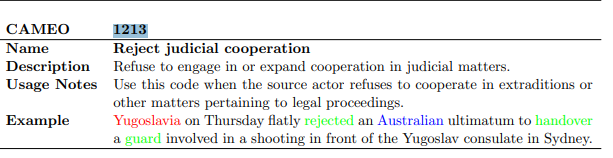
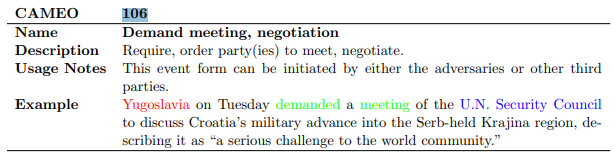

These are the on the codebook: https://data.gdeltproject.org/documentation/CAMEO.Manual.1.1b3.pdf?utm_source=chatgpt.com

But no goldstein values for 1213 and 106 here
https://gdeltproject.org/data/lookups/CAMEO.goldsteinscale.txt?utm_source=chatgpt.com


### Verify Goldstein Scores for Code 106

Code 106 has 1,550 records with existing Goldstein scores.

We will check whether these values are consistent before deciding if any corrections are needed.

In [55]:
# Select records with EventCode 106
code_106 = unrecognized_cameo[
    unrecognized_cameo["EventCode"] == "106"
]

# Count each Goldstein score
score_summary = (
    code_106["GoldsteinScale"]
    .value_counts(dropna=False)
    .rename_axis("GoldsteinScale")
    .reset_index(name="Count")
)

display(score_summary)

print("Total records:", len(code_106))
print("Unique Goldstein scores:", code_106["GoldsteinScale"].nunique())
print("Missing scores:", code_106["GoldsteinScale"].isna().sum())

,GoldsteinScale,Count
0,-5.0,1550


Total records: 1550
Unique Goldstein scores: 1
Missing scores: 0


Okay 106 has a goldstein score of -5.0 which is not in the code book but it is the goldstein score of 10. 
Similarly since 1213 doesnt have a goldsteinscore and we can find anything in the code book we will keep 121's score = -4.0

Adjust Missing Goldstein Scores

We found that EventCode 106 already has a consistent Goldstein score of -5.0, so no correction is needed.

EventCode 1213 has 94 missing Goldstein scores. We will use the score of its parent code 121 (-4.0) as an estimate.

The original GoldsteinScale column will remain unchanged. We will create a separate adjusted column and a flag to identify imputed values.

Records with EventCode --- or X will keep their missing scores.

In [56]:
def adjust_goldstein(df):

    df = df.copy()

    # Preserve original Goldstein scores
    df["GoldsteinScale_Adjusted"] = df["GoldsteinScale"].copy()

    # Identify records requiring imputation
    impute_mask = (
        df["EventCode"].eq("1213")
        & df["GoldsteinScale"].isna()
    ).fillna(False)

    # Impute using parent CAMEO code 121
    df.loc[impute_mask, "GoldsteinScale_Adjusted"] = -4.0

    # Record which values were imputed
    df["Flag_GoldsteinImputed"] = impute_mask

    return df


# Test on the full set of records with unrecognized codes
goldstein_test = adjust_goldstein(unrecognized_cameo)

# Verify results
print("Records tested:", len(goldstein_test))
print("Scores imputed:", int(goldstein_test["Flag_GoldsteinImputed"].sum()))
print("Original missing scores:", goldstein_test["GoldsteinScale"].isna().sum())
print("Remaining missing adjusted scores:",
      goldstein_test["GoldsteinScale_Adjusted"].isna().sum())

display(
    goldstein_test.groupby("EventCode", dropna=False).agg(
        Records=("EventCode", "size"),
        Original_Missing=("GoldsteinScale", lambda x: x.isna().sum()),
        Adjusted_Missing=("GoldsteinScale_Adjusted", lambda x: x.isna().sum()),
        Imputed=("Flag_GoldsteinImputed", "sum")
    ).reset_index()
)

Records tested: 1660
Scores imputed: 94
Original missing scores: 110
Remaining missing adjusted scores: 16


,EventCode,Records,Original_Missing,Adjusted_Missing,Imputed
0,---,15,15,15,0
1,106,1550,0,0,0
2,1213,94,94,0,94
3,X,1,1,1,0


### Update CAMEO Reference

We found that codes 106 and 1213 are valid CAMEO classifications but are missing from our GDELT reference file.

We will add these two codes to our reference list. The invalid codes --- and X will remain flagged.

The original event codes will not be changed.

In [57]:
# Add validated CAMEO codes missing from the lookup
additional_cameo_codes = {
    "106": "Demand meeting, negotiation",
    "1213": "Reject judicial cooperation"
}

# Create an extended reference without changing the original lookup
valid_cameo_event_codes_extended = (
    valid_cameo_event_codes
    | set(additional_cameo_codes.keys())
)

# Check the previously unrecognized records
for col in ["EventCode", "EventBaseCode", "EventRootCode"]:

    invalid = (
        unrecognized_cameo[col].notna()
        & ~unrecognized_cameo[col].isin(
            valid_cameo_event_codes_extended
        )
    )

    print(f"\n{col}")
    print("Remaining unrecognized records:", int(invalid.sum()))
    print(
        "Remaining unrecognized codes:",
        unrecognized_cameo.loc[invalid, col].unique().tolist()
    )


EventCode
Remaining unrecognized records: 16
Remaining unrecognized codes: ['---', 'X']

EventBaseCode
Remaining unrecognized records: 16
Remaining unrecognized codes: ['---', 'X']

EventRootCode
Remaining unrecognized records: 16
Remaining unrecognized codes: ['--', 'X']


Update the Cleaning Pipeline

The CAMEO reference now includes codes 106 and 1213.

We will update the cleaning pipeline to use this reference and apply the Goldstein score adjustment.

The original GoldsteinScale values will remain unchanged, and imputed values will be identified with a separate flag.

In [58]:
# Update CAMEO validation to use the extended reference
def validate_cameo(df):

    df = df.copy()

    # Validate CAMEO codes
    for col in ["EventCode", "EventBaseCode", "EventRootCode"]:

        codes = df[col].astype("string")

        df[f"Flag_Unrecognized_{col}"] = (
            codes.isna()
            | ~codes.isin(valid_cameo_event_codes_extended)
        )

    # Check EventCode and EventBaseCode hierarchy
    df["Flag_EventBaseMismatch"] = pd.Series(
        [
            not event.startswith(base)
            if pd.notna(event) and pd.notna(base)
            else True
            for event, base in zip(
                df["EventCode"],
                df["EventBaseCode"]
            )
        ],
        index=df.index
    )

    # Check EventBaseCode and EventRootCode hierarchy
    df["Flag_EventRootMismatch"] = pd.Series(
        [
            not base.startswith(root)
            if pd.notna(base) and pd.notna(root)
            else True
            for base, root in zip(
                df["EventBaseCode"],
                df["EventRootCode"]
            )
        ],
        index=df.index
    )

    return df


# Update combined cleaning function
def clean_gdelt(df):

    df = clean_gdelt_chunk(df)
    df = validate_cameo(df)
    df = adjust_goldstein(df)

    return df


# Test updated pipeline
updated_test = clean_gdelt(test_chunk_100k)

print("Rows:", len(updated_test))
print("Columns:", len(updated_test.columns))
print("Goldstein imputations:", int(updated_test["Flag_GoldsteinImputed"].sum()))

print("\nUnrecognized CAMEO codes:")
for col in ["EventCode", "EventBaseCode", "EventRootCode"]:
    print(
        col,
        int(updated_test[f"Flag_Unrecognized_{col}"].sum())
    )

print("\nOriginal data preserved:",
      updated_test[test_chunk_100k.columns].equals(test_chunk_100k))

Rows: 100000
Columns: 90
Goldstein imputations: 0

Unrecognized CAMEO codes:
EventCode 0
EventBaseCode 0
EventRootCode 0

Original data preserved: True


Verify Updated CAMEO and Goldstein Rules

Test the updated cleaning rules on records containing the previously unrecognized CAMEO codes.

We will confirm that codes 106 and 1213 are now recognized, that missing Goldstein scores are imputed correctly, and that malformed codes remain flagged.

In [59]:
# Apply updated validation to previously flagged records
verification_test = validate_cameo(unrecognized_cameo)
verification_test = adjust_goldstein(verification_test)

# Summarize results by event code
verification_summary = (
    verification_test
    .groupby("EventCode", dropna=False)
    .agg(
        Records=("EventCode", "size"),
        Unrecognized=("Flag_Unrecognized_EventCode", "sum"),
        Imputed=("Flag_GoldsteinImputed", "sum"),
        Remaining_Missing=("GoldsteinScale_Adjusted",
                           lambda x: x.isna().sum())
    )
    .reset_index()
)

display(verification_summary)

print("Total records:", len(verification_test))
print("Unrecognized event codes:",
      int(verification_test["Flag_Unrecognized_EventCode"].sum()))
print("Goldstein scores imputed:",
      int(verification_test["Flag_GoldsteinImputed"].sum()))
print("Remaining missing adjusted scores:",
      int(verification_test["GoldsteinScale_Adjusted"].isna().sum()))

,EventCode,Records,Unrecognized,Imputed,Remaining_Missing
0,---,15,15,0,15
1,106,1550,0,0,0
2,1213,94,0,94,0
3,X,1,1,0,1


Total records: 1660
Unrecognized event codes: 16
Goldstein scores imputed: 94
Remaining missing adjusted scores: 16


Prepare Updated Parquet Dataset

The updated cleaning rules have passed validation.

We will create a new set of Parquet files using the existing cleaned data. The changes include the extended CAMEO reference, adjusted Goldstein scores, and the imputation flag.

The previous cleaned files will be kept until the updated dataset has been validated.

In [60]:
from pathlib import Path

# Existing cleaned dataset
OLD_PARTITION_DIR = PARTITION_DIR

# New output directory
UPDATED_PARTITION_DIR = PROCESSED_DIR / "gdelt_cleaned_by_date_v2"

# Check that the new directory does not contain existing data
if UPDATED_PARTITION_DIR.exists():
    if any(UPDATED_PARTITION_DIR.iterdir()):
        raise FileExistsError(
            f"Output directory is not empty: {UPDATED_PARTITION_DIR}"
        )

UPDATED_PARTITION_DIR.mkdir(parents=True, exist_ok=True)

# Confirm input files
parquet_files = sorted(OLD_PARTITION_DIR.rglob("*.parquet"))

print("Existing Parquet files:", len(parquet_files))
print("Original records:", f"{total_rows:,}")
print("Original directory:", OLD_PARTITION_DIR)
print("Updated directory:", UPDATED_PARTITION_DIR)

Existing Parquet files: 6
Original records: 20,343,168
Original directory: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_data\processed\gdelt_cleaned_by_date
Updated directory: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_data\processed\gdelt_cleaned_by_date_v2


Save Updated Parquet Files

Update the cleaned dataset using the revised CAMEO reference and Goldstein score rules.

We will read the existing Parquet files in batches and save the updated data in a new directory.

The original dataset and previous cleaned files will remain unchanged.

In [61]:
import time
import pyarrow as pa
import pyarrow.parquet as pq

BATCH_SIZE = 100_000

start_time = time.time()
total_updated_rows = 0
total_imputations = 0
total_unrecognized = 0
updated_files = 0

# Prevent mixing results from previous runs
if any(UPDATED_PARTITION_DIR.rglob("*.parquet")):
    raise FileExistsError("Updated Parquet files already exist.")

try:
    for old_file in parquet_files:

        # Preserve the existing year/month partition structure
        relative_path = old_file.relative_to(OLD_PARTITION_DIR)
        new_file = UPDATED_PARTITION_DIR / relative_path

        new_file.parent.mkdir(parents=True, exist_ok=True)

        reader = pq.ParquetFile(old_file)
        writer = None
        file_rows = 0

        try:
            for batch in reader.iter_batches(batch_size=BATCH_SIZE):

                # Convert batch to Pandas
                df_batch = batch.to_pandas()

                # Apply revised CAMEO validation
                df_batch = validate_cameo(df_batch)

                # Add adjusted Goldstein scores
                df_batch = adjust_goldstein(df_batch)

                # Convert back to Arrow
                table = pa.Table.from_pandas(
                    df_batch,
                    preserve_index=False
                )

                # Create writer using the first batch schema
                if writer is None:
                    writer = pq.ParquetWriter(
                        new_file,
                        table.schema,
                        compression="snappy"
                    )

                writer.write_table(table)

                file_rows += len(df_batch)

                total_imputations += int(
                    df_batch["Flag_GoldsteinImputed"].sum()
                )

                total_unrecognized += int(
                    df_batch["Flag_Unrecognized_EventCode"].sum()
                )

        finally:
            if writer is not None:
                writer.close()

        total_updated_rows += file_rows
        updated_files += 1

        print(
            f"Updated {relative_path} | "
            f"Rows: {file_rows:,}"
        )

    # Create success marker only after all files are written
    (UPDATED_PARTITION_DIR / "_SUCCESS").touch()

except Exception:
    print("Processing interrupted. Do not use the incomplete v2 dataset.")
    raise

elapsed = time.time() - start_time

print("\nUpdate completed.")
print("Parquet files:", updated_files)
print("Total rows:", f"{total_updated_rows:,}")
print("Goldstein scores imputed:", total_imputations)
print("Unrecognized EventCodes:", total_unrecognized)
print("Processing time (minutes):", round(elapsed / 60, 2))
print("Updated directory:", UPDATED_PARTITION_DIR)

Updated DateAddedYear=2025\DateAddedMonth=01\part-0001.parquet | Rows: 3,667,945
Updated DateAddedYear=2025\DateAddedMonth=02\part-0001.parquet | Rows: 3,536,167
Updated DateAddedYear=2025\DateAddedMonth=03\part-0001.parquet | Rows: 3,896,037
Updated DateAddedYear=2025\DateAddedMonth=04\part-0001.parquet | Rows: 3,780,825
Updated DateAddedYear=2025\DateAddedMonth=05\part-0001.parquet | Rows: 3,867,054
Updated DateAddedYear=2025\DateAddedMonth=06\part-0001.parquet | Rows: 1,595,140

Update completed.
Parquet files: 6
Total rows: 20,343,168
Goldstein scores imputed: 94
Unrecognized EventCodes: 16
Processing time (minutes): 2.9
Updated directory: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_data\processed\gdelt_cleaned_by_date_v2


Validate Updated Parquet Files

Check that the updated Parquet files contain the same number of records as the previous dataset.

We will also verify the number of columns, check that all six files are readable, and confirm that the update completed successfully.

In [62]:
import pyarrow.parquet as pq

# Find updated Parquet files
updated_parquet_files = sorted(
    UPDATED_PARTITION_DIR.rglob("*.parquet")
)

validation_results_v2 = []

# Compare old and updated files
for old_file in parquet_files:

    relative_path = old_file.relative_to(OLD_PARTITION_DIR)
    new_file = UPDATED_PARTITION_DIR / relative_path

    old_metadata = pq.read_metadata(old_file)
    new_metadata = pq.read_metadata(new_file)

    validation_results_v2.append({
        "Partition": relative_path.parent.name,
        "Old_Rows": old_metadata.num_rows,
        "New_Rows": new_metadata.num_rows,
        "Old_Columns": old_metadata.num_columns,
        "New_Columns": new_metadata.num_columns,
        "Rows_Match": old_metadata.num_rows == new_metadata.num_rows
    })

validation_v2 = pd.DataFrame(validation_results_v2)

display(validation_v2)

# Final checks
print("Updated Parquet files:", len(updated_parquet_files))

print(
    "Total updated records:",
    f"{validation_v2['New_Rows'].sum():,}"
)

print(
    "All row counts match:",
    validation_v2["Rows_Match"].all()
)

print(
    "All files have 90 columns:",
    (validation_v2["New_Columns"] == 90).all()
)

print(
    "Success marker exists:",
    (UPDATED_PARTITION_DIR / "_SUCCESS").exists()
)

,Partition,Old_Rows,New_Rows,Old_Columns,New_Columns,Rows_Match
0,DateAddedMonth=01,3667945,3667945,88,90,True
1,DateAddedMonth=02,3536167,3536167,88,90,True
2,DateAddedMonth=03,3896037,3896037,88,90,True
3,DateAddedMonth=04,3780825,3780825,88,90,True
4,DateAddedMonth=05,3867054,3867054,88,90,True
5,DateAddedMonth=06,1595140,1595140,88,90,True


Updated Parquet files: 6
Total updated records: 20,343,168
All row counts match: True
All files have 90 columns: True
Success marker exists: True


Verify Goldstein Corrections

Compare the updated dataset with the previous cleaned version.

We will check that the original columns are unchanged, the 94 Goldstein scores were imputed correctly, and the 16 malformed CAMEO records remain flagged.

In [63]:
import pyarrow as pa
import pyarrow.parquet as pq

original_columns_preserved = True
total_imputed = 0
total_missing_adjusted = 0
total_unrecognized_codes = 0
total_checked = 0

# Columns expected to change because of the updated CAMEO reference
revised_flags = [
    "Flag_Unrecognized_EventCode",
    "Flag_Unrecognized_EventBaseCode",
    "Flag_Unrecognized_EventRootCode"
]

for old_file in parquet_files:

    relative_path = old_file.relative_to(OLD_PARTITION_DIR)
    new_file = UPDATED_PARTITION_DIR / relative_path

    old_reader = pq.ParquetFile(old_file)
    new_reader = pq.ParquetFile(new_file)

    old_columns = old_reader.schema_arrow.names

    # Exclude intentionally updated validation flags
    unchanged_columns = [
        col for col in old_columns
        if col not in revised_flags
    ]

    old_batches = old_reader.iter_batches(batch_size=100_000)
    new_batches = new_reader.iter_batches(batch_size=100_000)

    for old_batch, new_batch in zip(old_batches, new_batches):

        old_df = old_batch.to_pandas()
        new_df = new_batch.to_pandas()

        # Compare all columns that should remain unchanged
        if not old_df[unchanged_columns].equals(
            new_df[unchanged_columns]
        ):
            original_columns_preserved = False

        total_imputed += int(
            new_df["Flag_GoldsteinImputed"].sum()
        )

        total_missing_adjusted += int(
            new_df["GoldsteinScale_Adjusted"].isna().sum()
        )

        total_unrecognized_codes += int(
            new_df["Flag_Unrecognized_EventCode"].sum()
        )

        total_checked += len(new_df)

print("Records checked:", f"{total_checked:,}")
print("Unchanged columns preserved:", original_columns_preserved)
print("Goldstein scores imputed:", total_imputed)
print("Remaining missing adjusted scores:", total_missing_adjusted)
print("Unrecognized EventCodes:", total_unrecognized_codes)

Records checked: 20,343,168
Unchanged columns preserved: True
Goldstein scores imputed: 94
Remaining missing adjusted scores: 16
Unrecognized EventCodes: 16


12. Check Duplicate Event IDs

We previously found no duplicate event IDs in our smaller samples.

We will now check the full cleaned dataset to see whether any GLOBALEVENTID values appear more than once.

Repeated SOURCEURLs will not be treated as duplicates because one article can contain multiple events.

In [64]:
# Read only the event ID column from the cleaned Parquet files
event_id_parts = []

for file in updated_parquet_files:
    ids = pd.read_parquet(
        file,
        columns=["GLOBALEVENTID"]
    )["GLOBALEVENTID"]

    event_id_parts.append(ids)

# Combine event IDs
all_event_ids = pd.concat(
    event_id_parts,
    ignore_index=True
)

# Check duplicate IDs
duplicate_ids = all_event_ids.duplicated(keep=False)

duplicate_summary = pd.DataFrame({
    "Check": [
        "Total records",
        "Unique event IDs",
        "Records with duplicate IDs",
        "Distinct duplicated IDs",
        "Missing event IDs"
    ],
    "Count": [
        len(all_event_ids),
        all_event_ids.nunique(),
        int(duplicate_ids.sum()),
        int(all_event_ids[duplicate_ids].nunique()),
        int(all_event_ids.isna().sum())
    ]
})

display(duplicate_summary)

# Show repeated IDs if any exist
if duplicate_ids.any():
    display(
        all_event_ids[duplicate_ids]
        .value_counts()
        .head(20)
        .rename_axis("GLOBALEVENTID")
        .reset_index(name="Count")
    )

,Check,Count
0,Total records,20343168
1,Unique event IDs,20343168
2,Records with duplicate IDs,0
3,Distinct duplicated IDs,0
4,Missing event IDs,0


13. Cleaning Summary and Decision Log

The cleaning process is complete. We will summarize the data quality findings and document the decisions made during cleaning.

These records will help explain the cleaning process in the Phase 2 report.

In [65]:
# Create summary using previously validated results
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Total raw records",
        "Total cleaned records",
        "Original columns",
        "Cleaned columns",
        "Monthly Parquet partitions",
        "Duplicate event IDs",
        "Missing event IDs",
        "Goldstein scores imputed",
        "Remaining missing adjusted Goldstein scores",
        "Remaining unrecognized EventCodes"
    ],
    "Value": [
        20_343_168,
        total_updated_rows,
        58,
        90,
        len(updated_parquet_files),
        int(duplicate_ids.sum()),
        int(all_event_ids.isna().sum()),
        total_imputed,
        total_missing_adjusted,
        total_unrecognized_codes
    ]
})

# Save summary
SUMMARY_FILE = PROCESSED_DIR / "cleaning_summary.csv"

cleaning_summary.to_csv(SUMMARY_FILE, index=False)

display(cleaning_summary)

print("Summary saved:", SUMMARY_FILE)

,Metric,Value
0,Total raw records,20343168
1,Total cleaned records,20343168
2,Original columns,58
3,Cleaned columns,90
4,Monthly Parquet partitions,6
5,Duplicate event IDs,0
6,Missing event IDs,0
7,Goldstein scores imputed,94
8,Remaining missing adjusted Goldstein scores,16
9,Remaining unrecognized EventCodes,16


Summary saved: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_data\processed\cleaning_summary.csv


Cleaning Decision Log

Record the main decisions made during cleaning, including how we handled missing values, invalid codes, dates, and duplicate records.

This will help explain why certain values were retained, flagged, or adjusted.

In [66]:
# Document cleaning decisions
cleaning_decisions = [
    {
        "Issue": "CAMEO data types",
        "Finding": "Event codes contain leading zeros.",
        "Decision": "Store EventCode, EventBaseCode, and EventRootCode as strings."
    },
    {
        "Issue": "Unrecognized CAMEO codes",
        "Finding": "Codes 106 and 1213 were absent from the original lookup.",
        "Decision": "Add both to the extended CAMEO reference."
    },
    {
        "Issue": "Malformed CAMEO codes",
        "Finding": "16 records contain --- or X.",
        "Decision": "Retain records and flag invalid classifications."
    },
    {
        "Issue": "Missing Goldstein scores",
        "Finding": "94 records with EventCode 1213 have missing scores.",
        "Decision": "Impute -4.0 from parent code 121 in a separate adjusted column."
    },
    {
        "Issue": "Missing actor information",
        "Finding": "Actor country and identification fields contain substantial missing values.",
        "Decision": "Preserve missing values and create quality flags."
    },
    {
        "Issue": "Geographic codes",
        "Finding": "RB and OC were absent from the FIPS lookup.",
        "Decision": "Retain original codes and flag lookup mismatches."
    },
    {
        "Issue": "Geographic coordinates",
        "Finding": "Some records contain incomplete latitude/longitude pairs.",
        "Decision": "Flag incomplete coordinates without estimating missing values."
    },
    {
        "Issue": "Historical event dates",
        "Finding": "Some event dates are much earlier than DATEADDED.",
        "Decision": "Retain both dates and flag reporting delays greater than 30 days."
    },
    {
        "Issue": "Numerical outliers",
        "Finding": "Reporting counts and AvgTone contain statistical outliers.",
        "Decision": "Retain original values without capping or removing outliers."
    },
    {
        "Issue": "Repeated SOURCEURLs",
        "Finding": "Multiple event records can originate from the same article.",
        "Decision": "Retain repeated URLs because they do not necessarily indicate duplicates."
    },
    {
        "Issue": "Duplicate event IDs",
        "Finding": "No duplicated or missing GLOBALEVENTID values in the full dataset.",
        "Decision": "No deduplication required."
    }
]

# Create decision log
decision_log = pd.DataFrame(cleaning_decisions)

# Save as CSV
DECISION_LOG_FILE = PROCESSED_DIR / "cleaning_decision_log.csv"

decision_log.to_csv(DECISION_LOG_FILE, index=False)

display(decision_log)

print("Decision log saved:", DECISION_LOG_FILE)

,Issue,Finding,Decision
0,CAMEO data types,Event codes contain leading zeros.,"Store EventCode, EventBaseCode, and EventRootC..."
1,Unrecognized CAMEO codes,Codes 106 and 1213 were absent from the origin...,Add both to the extended CAMEO reference.
2,Malformed CAMEO codes,16 records contain --- or X.,Retain records and flag invalid classifications.
3,Missing Goldstein scores,94 records with EventCode 1213 have missing sc...,Impute -4.0 from parent code 121 in a separate...
4,Missing actor information,Actor country and identification fields contai...,Preserve missing values and create quality flags.
5,Geographic codes,RB and OC were absent from the FIPS lookup.,Retain original codes and flag lookup mismatches.
6,Geographic coordinates,Some records contain incomplete latitude/longi...,Flag incomplete coordinates without estimating...
7,Historical event dates,Some event dates are much earlier than DATEADDED.,Retain both dates and flag reporting delays gr...
8,Numerical outliers,Reporting counts and AvgTone contain statistic...,Retain original values without capping or remo...
9,Repeated SOURCEURLs,Multiple event records can originate from the ...,Retain repeated URLs because they do not neces...


Decision log saved: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_data\processed\cleaning_decision_log.csv


Test the Reusable Cleaning Script

Test the cleaning functions from src/data_cleaning.py using the same 100,000 records.

We will compare the results with our earlier notebook output to confirm that the script produces identical results.

In [68]:
from src.data_cleaning import clean_gdelt

# Run the cleaning function from the Python script
script_test = clean_gdelt(
    test_chunk_100k,
    dtype_map,
    valid_fips,
    valid_cameo_event_codes_extended
)

# Compare with the validated notebook results
print("Rows:", len(script_test))
print("Columns:", len(script_test.columns))

print(
    "Results match notebook:",
    script_test.equals(updated_test)
)

print(
    "Original data preserved:",
    script_test[test_chunk_100k.columns].equals(test_chunk_100k)
)

print(
    "Quality flags:",
    len([col for col in script_test.columns if col.startswith("Flag_")])
)

Rows: 100000
Columns: 90
Results match notebook: True
Original data preserved: True
Quality flags: 28
